# 💎 Prédiction du prix des diamants — notebook corrigé et enrichi

**Jeu de données :** 53 940 diamants (Kaggle — *Diamond Price Prediction Dataset*), 9 variables descriptives + le prix.
<br>
**Objectif :** construire un modèle capable d'estimer le prix d'un diamant à partir de ses caractéristiques
(poids, taille, qualité de la coupe, couleur, pureté), et comprendre ce qui fait le prix.

---

## Sommaire

1. Imports et configuration
2. Chargement et première inspection
3. Audit qualité et nettoyage
4. Analyse univariée (avec interprétations)
5. Analyse bivariée et paradoxe de Simpson (avec interprétations)
6. Feature engineering
7. Préparation de la modélisation
8. Comparaison des modèles (validation croisée)
9. Ablation : quel gain apporte le feature engineering ?
10. Optimisation des hyperparamètres et cible logarithmique
11. Évaluation finale et analyse des erreurs
12. Prédiction sur de nouveaux diamants
13. Sauvegarde du pipeline
14. Conclusion, limites et recommandations

## 1. Imports et configuration

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, median_absolute_error, r2_score)
from sklearn.model_selection import (KFold, RandomizedSearchCV, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")

# --- Affichage
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelsize": 10,
})

RANDOM_STATE = 42

import sklearn
print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 2.1.4 | numpy 1.26.4 | scikit-learn 1.4.2


## 2. Chargement et première inspection

Le fichier contient une première colonne sans nom (`Unnamed: 0`) qui n'est qu'un **identifiant de ligne** :
elle n'apporte aucune information et doit être supprimée pour éviter de la prendre pour une variable explicative.

| Variable | Signification | Type |
|---|---|---|
| `price` | prix en dollars US | cible (numérique) |
| `carat` | poids du diamant (0,2 – 5,01 ct) | numérique |
| `cut` | qualité de la taille : Fair → Good → Very Good → Premium → Ideal | **ordinale** |
| `color` | couleur : J (la moins blanche) → D (la plus blanche) | **ordinale** |
| `clarity` | pureté : I1 → SI2 → SI1 → VS2 → VS1 → VVS2 → VVS1 → IF | **ordinale** |
| `depth` | profondeur totale en % (hauteur / largeur moyenne) | numérique |
| `table` | largeur du plateau en % de la largeur maximale | numérique |
| `x`, `y`, `z` | longueur, largeur, hauteur en mm | numérique |

In [2]:
DATA_PATH = Path("dataset.csv")
raw = pd.read_csv(DATA_PATH)

print(f"Dimensions brutes : {raw.shape[0]:,} lignes x {raw.shape[1]} colonnes")
raw.head()

Dimensions brutes : 53,940 lignes x 11 colonnes


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.230,Ideal,E,SI2,61.500,55.000,326,3.950,3.980,2.430
1,2,0.210,Premium,E,SI1,59.800,61.000,326,3.890,3.840,2.310
2,3,0.230,Good,E,VS1,56.900,65.000,327,4.050,4.070,2.310
3,4,0.290,Premium,I,VS2,62.400,58.000,334,4.200,4.230,2.630
4,5,0.310,Good,J,SI2,63.300,58.000,335,4.340,4.350,2.750


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [4]:
# On écarte l'identifiant de ligne : il n'a aucun contenu métier
base = raw.drop(columns=[c for c in raw.columns if c.startswith("Unnamed")])

# Les variables catégorielles : sélection par exclusion des colonnes numériques
# (fonctionne aussi bien avec pandas 2.x qu'avec pandas 3.x)
cat_cols = base.select_dtypes(exclude="number").columns.tolist()
num_cols = base.select_dtypes(include="number").columns.tolist()
print("Catégorielles :", cat_cols)
print("Numériques    :", num_cols)

Catégorielles : ['cut', 'color', 'clarity']
Numériques    : ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']


In [5]:
base.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
carat,"53,940.000",0.798,0.474,0.200,0.400,0.700,1.040,5.010
depth,"53,940.000",61.749,1.433,43.000,61.000,61.800,62.500,79.000
table,"53,940.000",57.457,2.234,43.000,56.000,57.000,59.000,95.000
price,"53,940.000","3,932.800","3,989.440",326.000,950.000,"2,401.000","5,324.250","18,823.000"
x,"53,940.000",5.731,1.122,0.000,4.710,5.700,6.540,10.740
y,"53,940.000",5.735,1.142,0.000,4.720,5.710,6.540,58.900
z,"53,940.000",3.539,0.706,0.000,2.910,3.530,4.040,31.800


### Interprétation

* Le prix médian est de **2 401 $** alors que la moyenne atteint **3 933 $** : la distribution est **tirée vers
  la droite** par quelques diamants très chers (max 18 823 $).
* `carat` va de 0,2 à 5,01 ct pour une médiane de 0,70 : les gros diamants sont rares.
* `y` monte à **58,9 mm** et `z` à **31,8 mm**, alors que `x` plafonne à 10,74 mm. Un diamant ne peut pas être
  cinq fois plus large que long : ce sont des **erreurs de saisie**. Le `describe()` seul ne suffit donc pas à
  valider les données, il faut un contrôle physique (section 3).

## 3. Audit qualité et nettoyage

### 3.1 Valeurs manquantes, doublons, zéros

In [6]:
audit = pd.DataFrame({
    "contrôle": [
        "Valeurs manquantes (total)",
        "Lignes avec au moins un manquant",
        "Doublons exacts (hors identifiant)",
        "x = 0 (longueur nulle)",
        "y = 0 (largeur nulle)",
        "z = 0 (hauteur nulle)",
        "x, y ou z > 11 mm (impossible)",
    ],
    "nombre": [
        int(raw.isna().sum().sum()),
        int(raw.isna().any(axis=1).sum()),
        int(raw.drop(columns=["Unnamed: 0"]).duplicated().sum()),
        int((raw.x == 0).sum()),
        int((raw.y == 0).sum()),
        int((raw.z == 0).sum()),
        int((raw[["x", "y", "z"]] > 11).any(axis=1).sum()),
    ],
})
audit

,contrôle,nombre
0,Valeurs manquantes (total),0
1,Lignes avec au moins un manquant,0
2,Doublons exacts (hors identifiant),146
3,x = 0 (longueur nulle),8
4,y = 0 (largeur nulle),7
5,z = 0 (hauteur nulle),20
6,"x, y ou z > 11 mm (impossible)",3


**Aucune valeur manquante** au sens strict : le vrai problème de ce jeu de données est ailleurs — des
**zéros impossibles** (20 lignes) et des dimensions aberrantes. Supprimer les lignes plutôt que les imputer est
le bon choix : une dimension nulle rend le volume nul et fausse toute la géométrie ; on ne peut pas deviner la
vraie taille du diamant.

### 3.2 Contrôle de cohérence physique (le plus important)

La profondeur totale `depth` est, par définition, la hauteur rapportée à la largeur moyenne :

$$\text{depth}_{\text{calculé}} = \frac{200 \times z}{x + y}$$

Si l'écart avec le `depth` déclaré dépasse quelques points, la ligne est incohérente. De même, la **densité**
`carat / (x·y·z)` doit être à peu près constante (≈ 0,0061 pour un diamant) : c'est une constante physique, très
utile pour détecter les erreurs.

In [7]:
probe = raw.drop(columns=["Unnamed: 0"]).copy()
probe = probe[(probe[["x", "y", "z"]] > 0).all(axis=1)]

probe["depth_est"] = 200 * probe.z / (probe.x + probe.y)
probe["depth_gap"] = probe.depth - probe.depth_est
probe["density"] = probe.carat / (probe.x * probe.y * probe.z)

print(f"Densité : moyenne {probe.density.mean():.5f}, écart-type {probe.density.std():.5f}")
print(f"Écart de profondeur |gap| > 3 pts : {(probe.depth_gap.abs() > 3).sum()} ligne(s)")
probe.loc[probe.depth_gap.abs() > 3, ["carat", "depth", "table", "x", "y", "z", "price", "depth_gap"]].head(8)

Densité : moyenne 0.00613, écart-type 0.00018
Écart de profondeur |gap| > 3 pts : 38 ligne(s)


,carat,depth,table,x,y,z,price,depth_gap
2274,1.220,62.600,59.000,6.790,4.240,3.760,3156,-5.578
2941,1.000,62.800,63.000,6.260,6.190,3.190,3293,11.555
4518,1.000,43.000,59.000,6.320,6.270,3.970,3634,-20.066
4687,0.810,61.500,58.000,5.990,5.940,3.970,3674,-5.055
6341,1.000,44.000,53.000,6.310,6.240,4.120,4032,-21.657
10377,1.090,43.000,54.000,6.530,6.550,4.120,4778,-19.997
14029,1.220,61.100,57.000,6.900,5.920,4.220,5703,-4.735
14344,1.220,61.100,57.000,6.900,5.920,4.220,5807,-4.735


Exemples visibles ci-dessus : un diamant de 1,00 ct annoncé à `depth = 43 %` alors que ses dimensions
(x = 6,32 ; y = 6,27 ; z = 3,97) donnent 63 % ; un autre de 1,00 ct dont `z = 3,19 mm` implique 51 % et non 63 %.
Ces lignes sont supprimées : conserver une profondeur fausse reviendrait à apprendre au modèle un lien qui
n'existe pas.

In [8]:
def clean_diamonds(df):
    '''Nettoie le jeu de données et renvoie (données propres, rapport de nettoyage).'''
    steps = []
    out = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")]).copy()
    steps.append(("Lignes brutes", len(df), len(out)))

    out = out.drop_duplicates()
    steps.append(("Doublons exacts supprimés", len(df), len(out)))

    dims = out[["x", "y", "z"]]
    valid_geom = dims.gt(0).all(axis=1) & dims.le(11).all(axis=1) & out.z.le(8)
    out = out[valid_geom]
    steps.append(("Géométrie valide (0 < x,y <= 11 mm ; 0 < z <= 8 mm)", len(df), len(out)))

    out = out[out.table.between(43, 75) & out.depth.between(45, 75)]
    steps.append(("Table et profondeur dans les bornes physiques", len(df), len(out)))

    gap = (out.depth - 200 * out.z / (out.x + out.y)).abs()
    out = out[gap.le(3)]
    steps.append(("Cohérence depth déclaré / depth calculé", len(df), len(out)))

    report = pd.DataFrame(steps, columns=["Étape", "Lignes initiales", "Lignes restantes"])
    report["Supprimées (cumul)"] = report["Lignes initiales"] - report["Lignes restantes"]
    return out.reset_index(drop=True), report


df, cleaning_report = clean_diamonds(raw)
cleaning_report

,Étape,Lignes initiales,Lignes restantes,Supprimées (cumul)
0,Lignes brutes,53940,53940,0
1,Doublons exacts supprimés,53940,53794,146
2,"Géométrie valide (0 < x,y <= 11 mm ; 0 < z <= ...",53940,53772,168
3,Table et profondeur dans les bornes physiques,53940,53764,176
4,Cohérence depth déclaré / depth calculé,53940,53732,208


In [9]:
print(f"Lignes conservées : {len(df):,} / {len(raw):,} ({len(df)/len(raw):.2%})")
print("Manquants restants :", int(df.isna().sum().sum()))
print("Doublons restants  :", int(df.duplicated().sum()))

Lignes conservées : 53,732 / 53,940 (99.61%)
Manquants restants : 0
Doublons restants  : 0


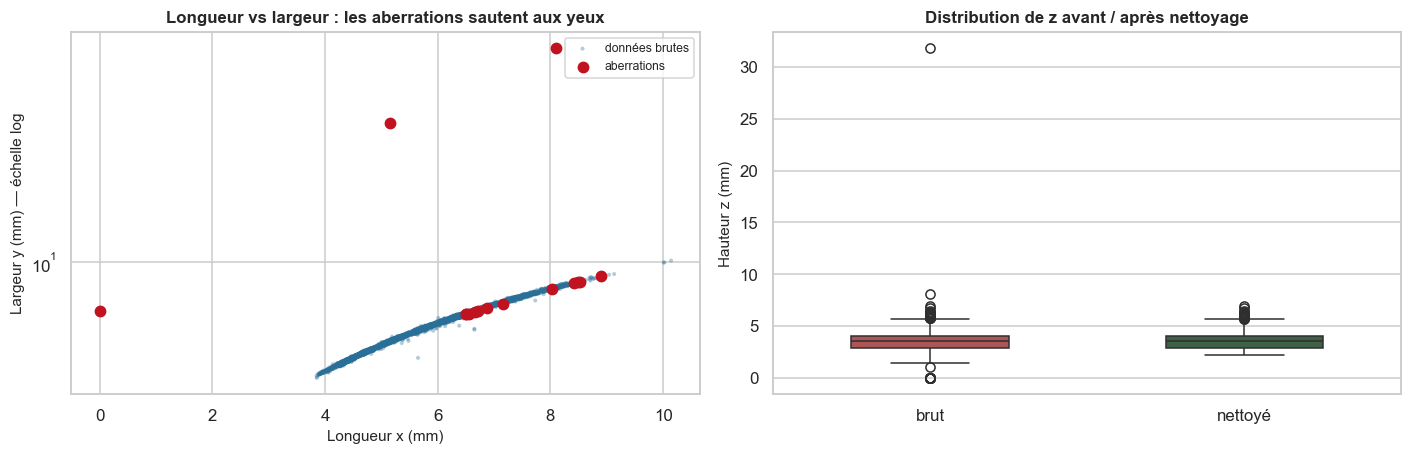

In [10]:
# Contrôle visuel : avant / après
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

sample = raw.sample(6000, random_state=RANDOM_STATE)
axes[0].scatter(sample.x, sample.y, s=7, alpha=0.35, color="#2a6f97", edgecolor="none", label="données brutes")
outliers = raw[(raw.y > 11) | (raw[["x", "y", "z"]] == 0).any(axis=1)]
axes[0].scatter(outliers.x, outliers.y, s=45, color="#c1121f", zorder=3, label="aberrations")
axes[0].set(yscale="log", xlabel="Longueur x (mm)", ylabel="Largeur y (mm) — échelle log",
            title="Longueur vs largeur : les aberrations sautent aux yeux")
axes[0].legend(fontsize=8)

box = pd.concat([
    pd.DataFrame({"état": "brut", "z": raw.z}),
    pd.DataFrame({"état": "nettoyé", "z": df.z}),
])
sns.boxplot(data=box, x="état", y="z", ax=axes[1], palette=["#bc4749", "#386641"], width=0.5)
axes[1].set(xlabel="", ylabel="Hauteur z (mm)", title="Distribution de z avant / après nettoyage")

plt.tight_layout()
plt.show()

### Interprétation

* À gauche, les points rouges sont **hors de la diagonale** : un `y` de 58,9 mm pour un `x` de 8 mm ne décrit
  aucun objet réel. Ce sont ces lignes qui, conservées, expliquaient une partie des résidus extrêmes de la v1.
* À droite, la boîte « nettoyée » a perdu des valeurs extrêmes sans perdre de masse : le nettoyage retire
  **0,4 %** des lignes mais supprime l'essentiel du bruit de mesure. Le prix médian, lui, ne bouge pas.

## 4. Analyse univariée

### 4.1 La cible : `price`

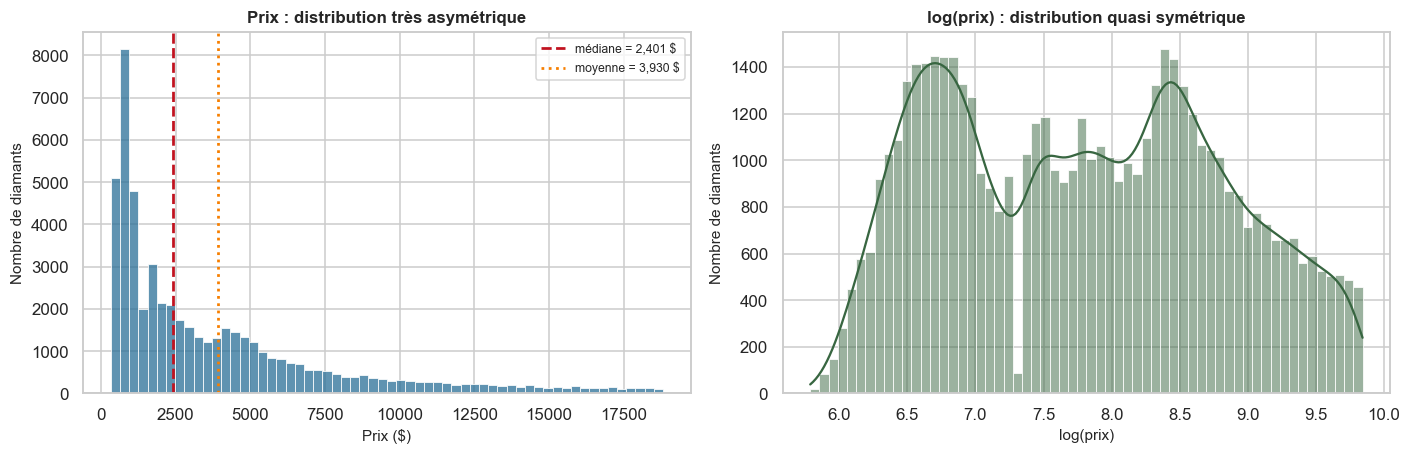

Asymétrie (skewness) du prix        : 1.619
Asymétrie (skewness) de log(prix)   : 0.115


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

sns.histplot(df.price, bins=60, ax=axes[0], color="#2a6f97")
axes[0].axvline(df.price.median(), color="#c1121f", ls="--", lw=1.8,
                label=f"médiane = {df.price.median():,.0f} $")
axes[0].axvline(df.price.mean(), color="#f77f00", ls=":", lw=1.8,
                label=f"moyenne = {df.price.mean():,.0f} $")
axes[0].set(xlabel="Prix ($)", ylabel="Nombre de diamants", title="Prix : distribution très asymétrique")
axes[0].legend(fontsize=8)

sns.histplot(np.log(df.price), bins=60, ax=axes[1], color="#386641", kde=True)
axes[1].set(xlabel="log(prix)", ylabel="Nombre de diamants", title="log(prix) : distribution quasi symétrique")

plt.tight_layout()
plt.show()

print(f"Asymétrie (skewness) du prix        : {df.price.skew():.3f}")
print(f"Asymétrie (skewness) de log(prix)   : {np.log(df.price).skew():.3f}")

### Interprétation

* Le prix est **fortement asymétrique à droite** (skewness **1,62**) : une longue queue de diamants chers. Un
  modèle linéaire qui minimise les moindres carrés est mal adapté à cette forme et se laisse dominer par les
  valeurs extrêmes.
* Le logarithme du prix est **presque symétrique** (skewness **0,12**). Modéliser `log(prix)` transforme une
  relation multiplicative (le prix croît en puissance du carat) en relation additive : c'est la raison du gain
  de performance observé en section 10.
* Conséquence pratique : l'erreur relative (MAPE) est plus pertinente que l'erreur absolue pour comparer des
  modèles sur ce type de cible.

### 4.2 Le poids : `carat`

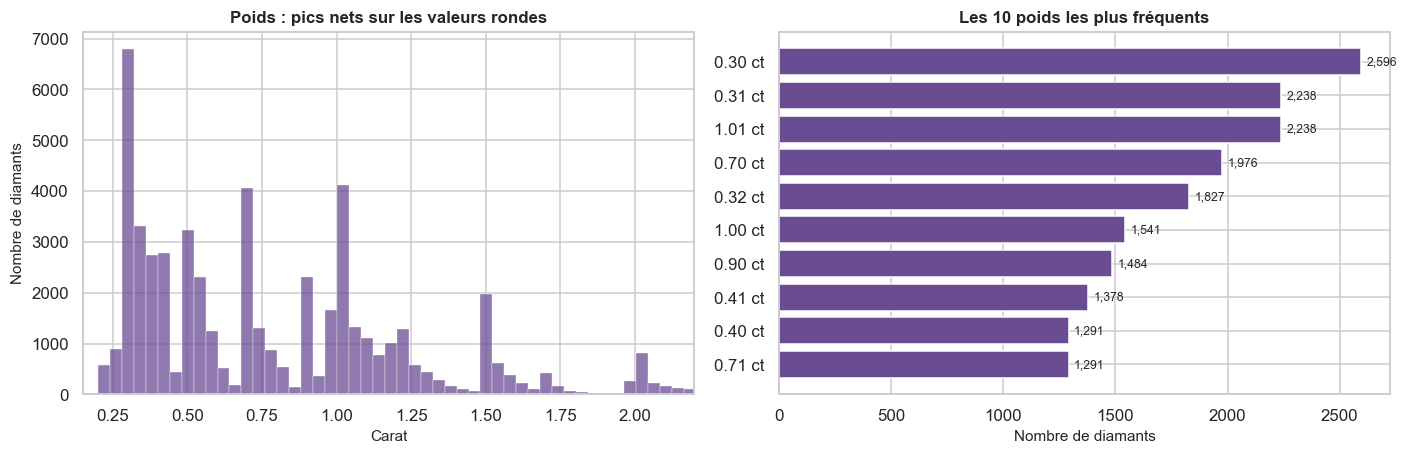

Part des diamants >= 1 ct : 35.3%


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

sns.histplot(df.carat, bins=120, ax=axes[0], color="#6a4c93")
axes[0].set(xlim=(0.15, 2.2), xlabel="Carat", ylabel="Nombre de diamants",
            title="Poids : pics nets sur les valeurs rondes")

top = df.carat.value_counts().head(10)[::-1]
axes[1].barh([f"{v:.2f} ct" for v in top.index], top.values, color="#6a4c93")
axes[1].set(xlabel="Nombre de diamants", title="Les 10 poids les plus fréquents")
for i, (v, n) in enumerate(zip(top.index, top.values)):
    axes[1].text(n + 25, i, f"{n:,}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

print(f"Part des diamants >= 1 ct : {(df.carat >= 1).mean():.1%}")

### Interprétation

* La distribution est **très concentrée sous 1 ct** : 65 % des diamants pèsent moins d'un carat, et le pic
  principal est à **0,30 ct**.
* Les poids sont **discrets et « ronds »** : 0,30 / 0,31 / 0,70 / 1,00 / 1,01 ct dominent. C'est une réalité du
  marché (les pierres sont taillées pour atteindre un poids commercial) et cela signifie que `carat` n'est pas
  une variable continue « lisse » : deux pierres à 0,99 et 1,01 ct n'ont pas le même prix.
* Le seuil de **1 ct** est un cap psychologique : le prix au carat y fait un saut. C'est exactement ce que
  montre la figure suivante.

### 4.3 Les variables de qualité (ordinales)

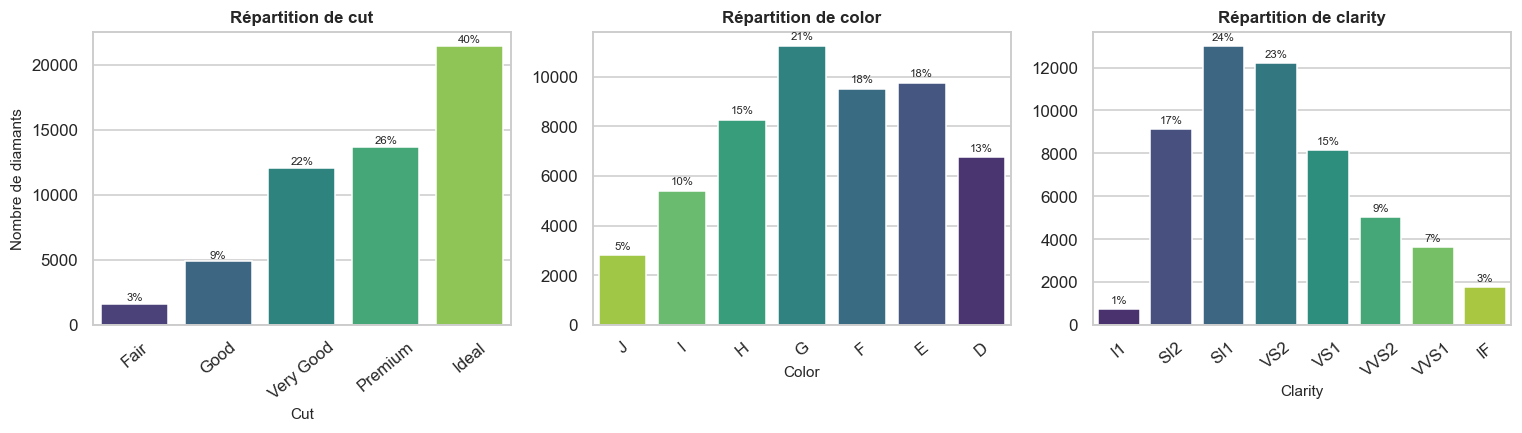

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.1))

for ax, (col, order, palette) in zip(axes, [
    ("cut", ["Fair", "Good", "Very Good", "Premium", "Ideal"], "viridis"),
    ("color", ["J", "I", "H", "G", "F", "E", "D"], "viridis_r"),
    ("clarity", ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"], "viridis"),
]):
    counts = df[col].value_counts().reindex(order)
    sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=palette, hue=counts.index, legend=False)
    ax.set(title=f"Répartition de {col}", xlabel=col.capitalize(), ylabel="Nombre de diamants" if col == "cut" else "")
    for i, v in enumerate(counts.values):
        ax.text(i, v + 250, f"{v/len(df):.0%}", ha="center", fontsize=7.5)
    ax.tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

### Interprétation

* La gamme est **déséquilibrée** : 40 % de `Ideal` contre 3 % de `Fair`, et 1,4 % de `I1`. Les modalités rares
  (Fair, I1, IF) seront les plus difficiles à prédire : le modèle a peu d'exemples pour apprendre leur effet.
* L'échelle est **ordonnée** (Fair < Good < Very Good < Premium < Ideal, J < I < … < D, I1 < … < IF). La v1 les
  traitait en one-hot, ce qui détruit cette information d'ordre et éclate 3 colonnes en 18. La section 9
  montre que l'encodage ordinal est **plus performant** que le one-hot sur ce jeu de données.

## 5. Analyse bivariée : le prix et ses moteurs

### 5.1 Prix vs carat — la relation dominante

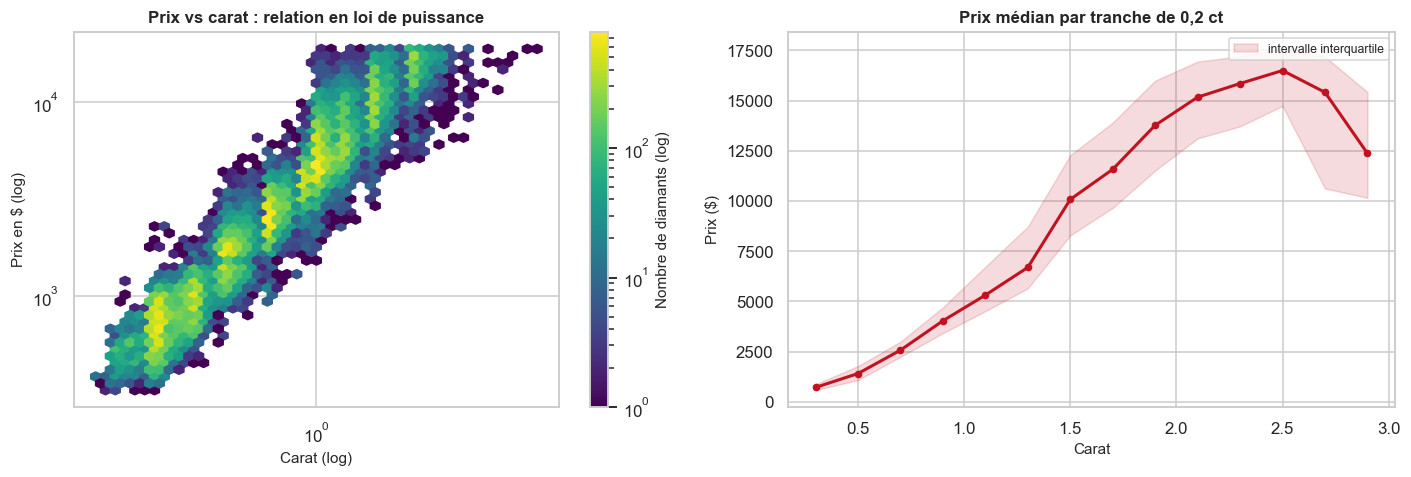

Corrélation carat / prix (Pearson)  : 0.922
Corrélation log(carat) / log(prix)  : 0.966


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

hb = axes[0].hexbin(df.carat, df.price, gridsize=45, xscale="log", yscale="log",
                    cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[0], label="Nombre de diamants (log)")
axes[0].set(xlabel="Carat (log)", ylabel="Prix en $ (log)",
            title="Prix vs carat : relation en loi de puissance")

bins = pd.cut(df.carat, np.arange(0.2, 3.2, 0.2))
med = df.groupby(bins, observed=True).price.median()
axes[1].plot([b.mid for b in med.index], med.values, "o-", color="#c1121f", lw=2, ms=4)
axes[1].fill_between([b.mid for b in med.index],
                     df.groupby(bins, observed=True).price.quantile(.25).values,
                     df.groupby(bins, observed=True).price.quantile(.75).values,
                     color="#c1121f", alpha=0.15, label="intervalle interquartile")
axes[1].set(xlabel="Carat", ylabel="Prix ($)", title="Prix médian par tranche de 0,2 ct")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"Corrélation carat / prix (Pearson)  : {df.carat.corr(df.price):.3f}")
print(f"Corrélation log(carat) / log(prix)  : {np.log(df.carat).corr(np.log(df.price)):.3f}")

### Interprétation

* `carat` est de loin le premier déterminant du prix (**r = 0,92**). Sur l'échelle log-log, le nuage est
  presque rectiligne : le prix suit une **loi de puissance** du poids, $prix \approx a \cdot carat^{b}$.
* La dispersion verticale **augmente avec le carat** (hétéroscédasticité) : à 0,3 ct, tous les diamants coûtent
  presque la même chose ; à 2 ct, les prix vont du simple au triple selon la couleur et la pureté. Un modèle à
  erreur absolue constante est donc mal calibré : d'où l'intérêt de la cible logarithmique.
* L'intervalle interquartile (droite) s'élargit lui aussi : c'est le signe que **d'autres variables comptent**,
  et qu'un modèle à une seule variable ne suffira pas.

### 5.2 Prix vs qualité : un résultat contre-intuitif (paradoxe de Simpson)

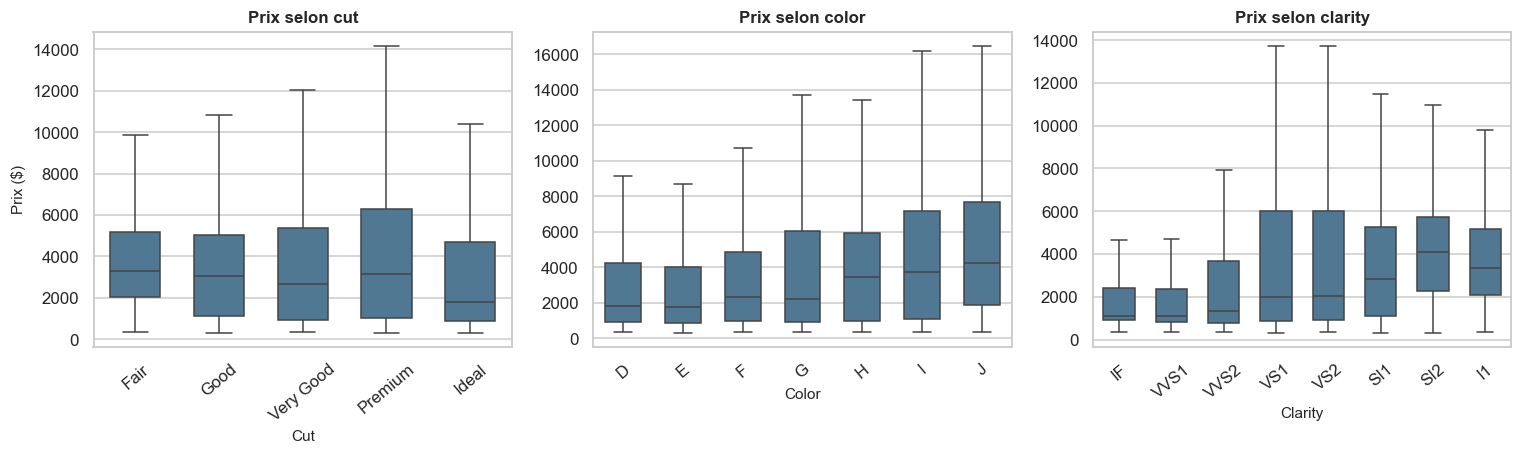

Prix MÉDIAN selon cut   : {'Ideal': 1813.0, 'Very Good': 2648.0, 'Good': 3042.0, 'Premium': 3177.5, 'Fair': 3281.0}
Prix MÉDIAN selon color : {'E': 1739.0, 'D': 1842.0, 'G': 2241.0, 'F': 2345.0, 'H': 3447.0, 'I': 3720.0, 'J': 4235.0}
Prix MÉDIAN selon clarity: {'IF': 1080.0, 'VVS1': 1094.0, 'VVS2': 1316.0, 'VS1': 2006.5, 'VS2': 2056.0, 'SI1': 2822.0, 'I1': 3351.0, 'SI2': 4071.0}

Poids moyen selon cut    : {'Fair': 1.04, 'Good': 0.85, 'Ideal': 0.7, 'Premium': 0.89, 'Very Good': 0.81}
Poids moyen selon color  : {'D': 0.66, 'E': 0.66, 'F': 0.74, 'G': 0.77, 'H': 0.91, 'I': 1.02, 'J': 1.16}
Poids moyen selon clarity: {'I1': 1.28, 'IF': 0.51, 'SI1': 0.85, 'SI2': 1.08, 'VS1': 0.73, 'VS2': 0.76, 'VVS1': 0.5, 'VVS2': 0.6}


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

for ax, (col, order) in zip(axes, [
    ("cut", ["Fair", "Good", "Very Good", "Premium", "Ideal"]),
    ("color", ["D", "E", "F", "G", "H", "I", "J"]),
    ("clarity", ["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"]),
]):
    sns.boxplot(data=df, x=col, y="price", order=order, ax=ax, color="#457b9d", width=0.6,
                showfliers=False)
    ax.set(title=f"Prix selon {col}", xlabel=col.capitalize(), ylabel="Prix ($)" if col == "cut" else "")
    ax.tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

print("Prix MÉDIAN selon cut   :", df.groupby("cut").price.median().sort_values().to_dict())
print("Prix MÉDIAN selon color :", df.groupby("color").price.median().sort_values().to_dict())
print("Prix MÉDIAN selon clarity:", df.groupby("clarity").price.median().sort_values().to_dict())
print("\nPoids moyen selon cut    :", df.groupby("cut").carat.mean().round(2).to_dict())
print("Poids moyen selon color  :", df.groupby("color").carat.mean().round(2).to_dict())
print("Poids moyen selon clarity:", df.groupby("clarity").carat.mean().round(2).to_dict())

### Interprétation — attention, piège

* Le prix médian **augmente quand la qualité se dégrade** : 1 813 $ pour `Ideal` contre 3 281 $ pour `Fair` ;
  1 739 $ pour `E` contre 4 235 $ pour `J`. Pris au pied de la lettre, cela dirait qu'une mauvaise coupe
  rend un diamant plus cher, ce qui est **faux**.
* La cause est une **variable de confusion** : les pierres mal taillées ou mal colorées sont souvent **plus
  grosses**. Le poids moyen est de **0,70 ct** pour `Ideal` mais de **1,04 ct** pour `Fair` ; de 0,66 ct pour `D`
  contre **1,16 ct** pour `J`. Le carat, qui domine le prix, écrase l'effet de la qualité.
* C'est un **paradoxe de Simpson** : la relation observée sur l'ensemble s'inverse quand on contrôle par le
  poids. Une analyse qui s'arrête à ces boîtes tire donc une conclusion commerciale erronée. La v1 de ce
  notebook ne faisait pas ce contrôle ; on le fait immédiatement ci-dessous.

In [16]:
# Comparaison à poids comparable : la tranche 0,9 - 1,1 ct
band = df[df.carat.between(0.9, 1.1)].copy()
band["price_per_carat"] = band.price / band.carat

print(f"{len(band):,} diamants dans la tranche 0,9 – 1,1 ct")
print("\nPrix MÉDIAN (bande) selon cut :",
      band.groupby("cut").price.median().reindex(["Fair", "Good", "Very Good", "Premium", "Ideal"]).round(0).to_dict())
print("Prix/carat MÉDIAN (bande) selon cut :",
      band.groupby("cut").price_per_carat.median().reindex(["Fair", "Good", "Very Good", "Premium", "Ideal"]).round(0).to_dict())
print("\nPrix/carat MÉDIAN (bande) selon color :",
      band.groupby("color").price_per_carat.median().reindex(["D", "E", "F", "G", "H", "I", "J"]).round(0).to_dict())
print("Prix/carat MÉDIAN (bande) selon clarity :",
      band.groupby("clarity").price_per_carat.median().reindex(
          ["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"]).round(0).to_dict())

10,298 diamants dans la tranche 0,9 – 1,1 ct

Prix MÉDIAN (bande) selon cut : {'Fair': 3733.0, 'Good': 4310.0, 'Very Good': 4691.0, 'Premium': 4672.0, 'Ideal': 5222.0}
Prix/carat MÉDIAN (bande) selon cut : {'Fair': 3763.0, 'Good': 4432.0, 'Very Good': 4785.0, 'Premium': 4702.0, 'Ideal': 5103.0}

Prix/carat MÉDIAN (bande) selon color : {'D': 5096.0, 'E': 4977.0, 'F': 4940.0, 'G': 5187.0, 'H': 4514.0, 'I': 4014.0, 'J': 3590.0}
Prix/carat MÉDIAN (bande) selon clarity : {'IF': 9871.0, 'VVS1': 8212.0, 'VVS2': 8131.0, 'VS1': 6290.0, 'VS2': 5702.0, 'SI1': 4702.0, 'SI2': 4088.0, 'I1': 2736.0}


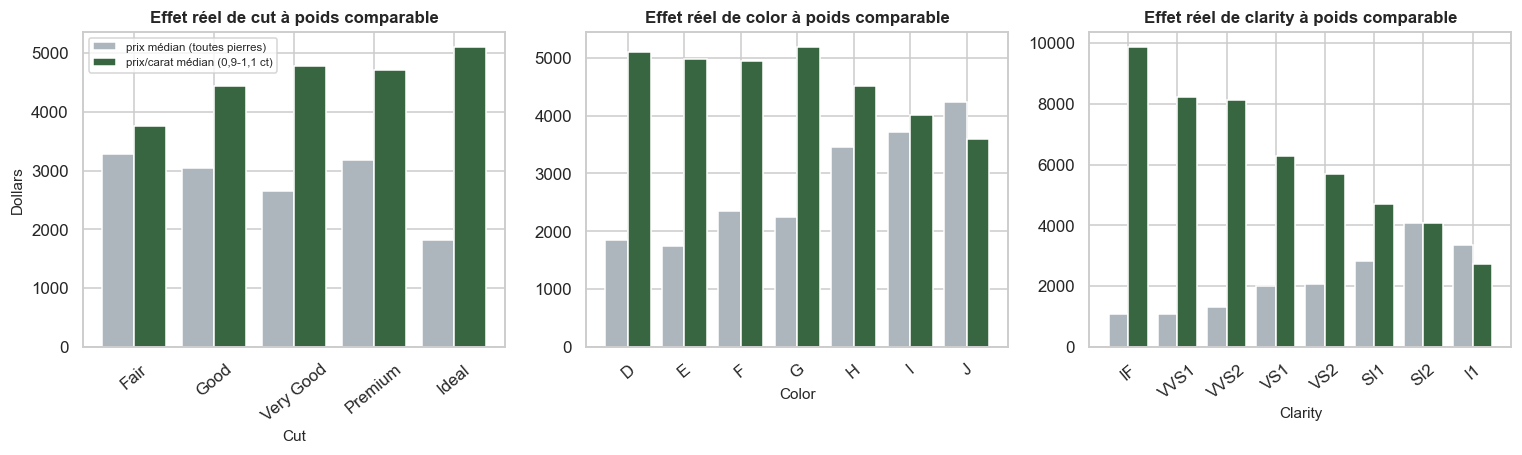

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3))

pairs = [
    ("cut", ["Fair", "Good", "Very Good", "Premium", "Ideal"]),
    ("color", ["D", "E", "F", "G", "H", "I", "J"]),
    ("clarity", ["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"]),
]
for ax, (col, order) in zip(axes, pairs):
    all_med = df.groupby(col).price.median().reindex(order)
    band_med = band.groupby(col).price_per_carat.median().reindex(order)
    x = np.arange(len(order))
    ax.bar(x - 0.2, all_med.values, width=0.4, label="prix médian (toutes pierres)", color="#adb5bd")
    ax.bar(x + 0.2, band_med.values, width=0.4, label="prix/carat médian (0,9-1,1 ct)", color="#386641")
    ax.set_xticks(x, order, rotation=40)
    ax.set(title=f"Effet réel de {col} à poids comparable", xlabel=col.capitalize(),
           ylabel="Dollars" if col == "cut" else "")
    if col == "cut":
        ax.legend(fontsize=7.5)

plt.tight_layout()
plt.show()

### Interprétation — l'effet réel de la qualité

À poids comparable (0,9 – 1,1 ct), la hiérarchie **redevient celle attendue** :

| Variable | Sens de l'effet (prix/carat médian) |
|---|---|
| `cut` | Fair **3 763 $** < Good 4 432 $ < Very Good 4 785 $ ≈ Premium 4 702 $ < Ideal **5 103 $** |
| `color` | J **3 590 $** < I 4 014 $ < H 4 514 $ < F 4 940 $ ≈ E 4 977 $ ≈ D **5 096 $** |
| `clarity` | I1 **2 736 $** < SI2 4 088 $ < SI1 4 702 $ < VS2 5 702 $ < VS1 6 290 $ < VVS2 8 131 $ < VVS1 8 212 $ < IF **9 871 $** |

Trois enseignements :

1. **La pureté est le facteur de qualité le plus puissant** : de I1 à IF, le prix au carat est multiplié par
   **3,6**. À poids donné, c'est le premier arbitrage d'un acheteur.
2. **La couleur pèse environ 40 %** (J → D : +42 %), avec un plateau entre D, E, F et G (les pierres
   « incolores » se valent presque) puis une chute nette à partir de H.
3. **`cut` a l'effet le plus faible** (Fair → Ideal : +36 %, mais Fair ne pèse que 3 % du marché) et
   `Premium` est **au même niveau que Very Good** : la « Premium » n'est pas un cran de qualité supérieur,
   c'est une catégorie de taille qui privilégie le rendement. La hiérarchie GIA n'est donc pas strictement
   croissante en prix — un point que le one-hot ne peut pas représenter et que l'encodage ordinal suppose
   (limite à garder en tête).

> ⚠️ La tranche 0,9–1,1 ct reste un contrôle **approximatif** : le prix au carat varie lui-même avec le poids.
> C'est la raison pour laquelle on passe à un modèle multivarié capable de contrôler toutes les variables
> simultanément.

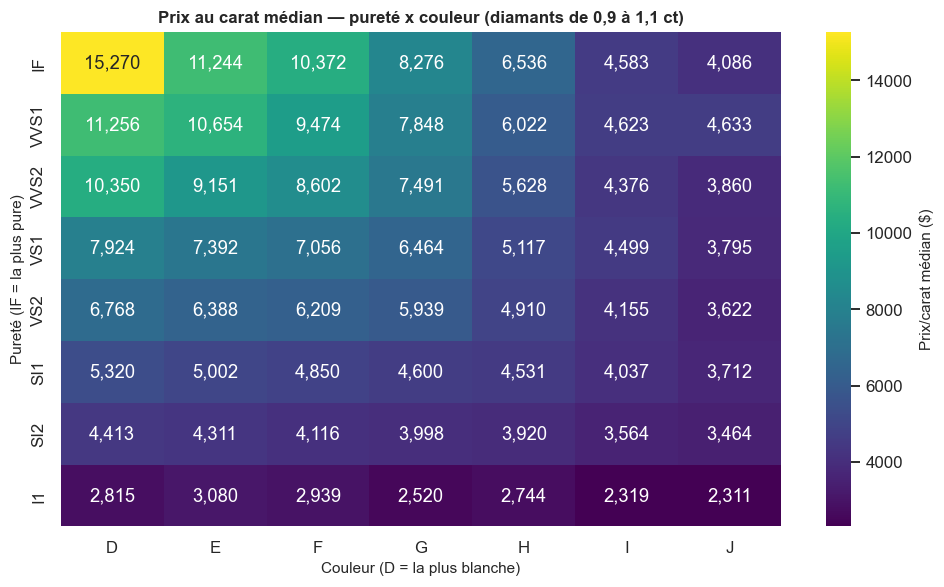

In [18]:
# Structure de prix : couleur x pureté, à poids comparable
pivot = band.pivot_table(index="clarity", columns="color", values="price_per_carat", aggfunc="median")
pivot = pivot.reindex(index=["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"],
                      columns=["D", "E", "F", "G", "H", "I", "J"])

plt.figure(figsize=(9, 5.5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="viridis", cbar_kws={"label": "Prix/carat médian ($)"})
plt.title("Prix au carat médian — pureté x couleur (diamants de 0,9 à 1,1 ct)")
plt.xlabel("Couleur (D = la plus blanche)")
plt.ylabel("Pureté (IF = la plus pure)")
plt.tight_layout()
plt.show()

### Interprétation

* Le dégradé est **régulier dans les deux directions** : la couleur et la pureté agissent de façon
  **multiplicative et indépendante**, du coin I1/J (~2 800 $/ct) au coin IF/D (~10 700 $/ct), soit un facteur
  proche de **4** pour un même poids.
* Les écarts sont plus serrés à gauche (pierres blanches et pures) qu'à droite : passer de J à I coûte moins
  cher que passer de D à F. Les pierres de tête de gamme sont rares, donc très chères.
* Une cellule manquante (IF/I) signifie qu'il n'existe presque pas de pierre de 1 ct à la fois très pure et
  très colorée : dans les données, la qualité est **corrélée négativement au poids** (les grosses pierres sont
  plus souvent imparfaites). Le modèle doit apprendre ces interactions, pas seulement des effets additifs.

### 5.3 Profondeur et table : des effets faibles mais non linéaires

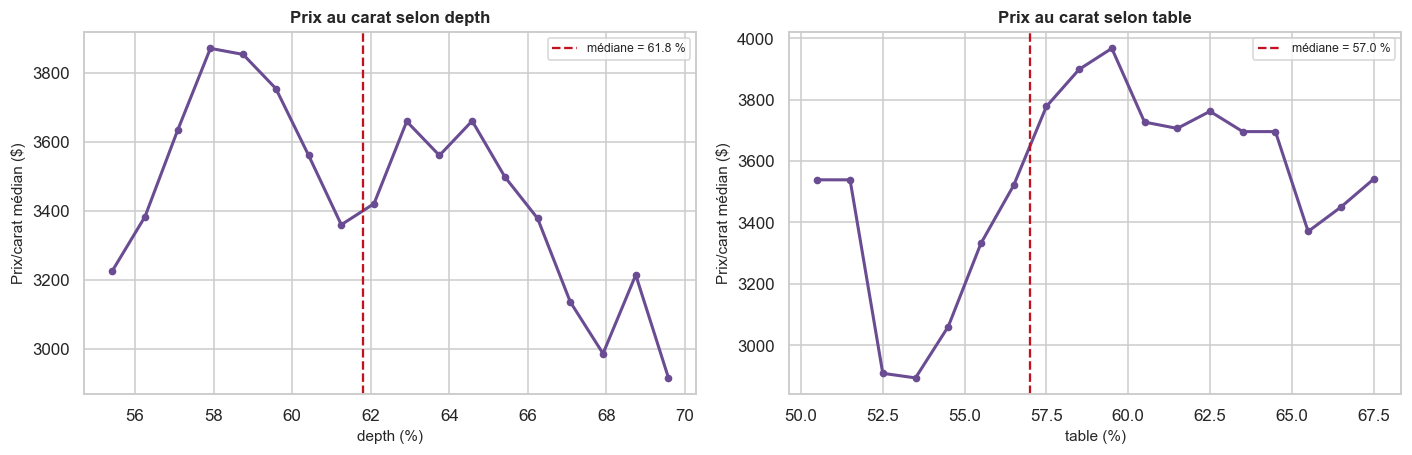

Corrélation depth / prix        : -0.011
Corrélation table / prix        : +0.126
Corrélation depth / prix/carat  : -0.036


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

for ax, (col, lim) in zip(axes, [("depth", (55, 70)), ("table", (50, 68))]):
    sub = df[df[col].between(*lim)].assign(price_per_carat=lambda d: d.price / d.carat)
    b = pd.cut(sub[col], bins=18)
    med = sub.groupby(b, observed=True).price_per_carat.median()
    ax.plot([i.mid for i in med.index], med.values, "o-", color="#6a4c93", lw=2, ms=4)
    ax.axvline(sub[col].median(), color="#c1121f", ls="--", lw=1.5,
               label=f"médiane = {sub[col].median():.1f} %")
    ax.set(xlabel=f"{col} (%)", ylabel="Prix/carat médian ($)",
           title=f"Prix au carat selon {col}")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"Corrélation depth / prix        : {df.depth.corr(df.price):+.3f}")
print(f"Corrélation table / prix        : {df.table.corr(df.price):+.3f}")
print(f"Corrélation depth / prix/carat  : {df.depth.corr(df.price/df.carat):+.3f}")

### Interprétation

* Les corrélations linéaires sont **quasi nulles** (`depth` : −0,01 ; `table` : +0,13), mais les courbes ne
  sont **pas plates** : le prix au carat est maximal autour d'une profondeur de **61–62 %** et d'un plateau de
  **56–58 %**. C'est exactement la zone considérée comme idéale par les gemmologues (un diamant trop plat perd
  en brillance, trop profond il perd de la lumière).
* Cette relation en **cloche** explique pourquoi la corrélation linéaire ne la voit pas : c'est une information
  que les arbres de décision capturent naturellement, contrairement à une régression linéaire.
* Effet modeste en amplitude (quelques pourcents), mais il devient utile **à poids et pureté égaux**, là où le
  modèle doit départager deux pierres par ailleurs identiques.

### 5.4 Matrice de corrélation (variables numériques et ordinales encodées)

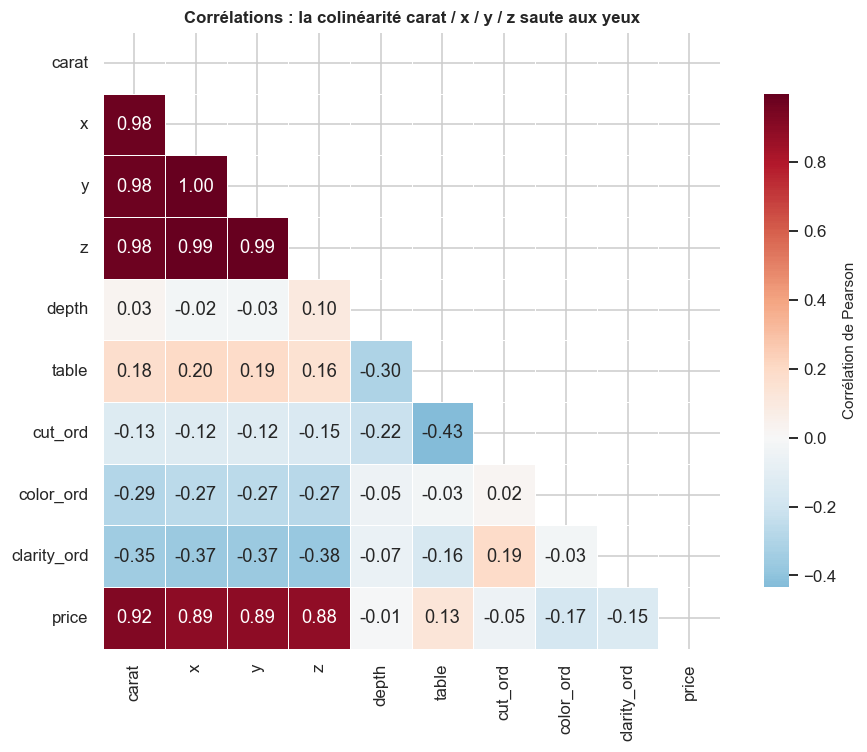

Corrélations avec le prix :
carat          0.922
y              0.889
x              0.887
z              0.883
color_ord     -0.172
clarity_ord   -0.146
table          0.126
cut_ord       -0.052
depth         -0.011


In [20]:
corr_cols = ["carat", "x", "y", "z", "depth", "table",
             "cut_ord", "color_ord", "clarity_ord", "price"]

tmp = df.copy()
tmp["cut_ord"] = tmp.cut.map({"Fair": 1, "Good": 2, "Very Good": 3, "Premium": 4, "Ideal": 5})
tmp["color_ord"] = tmp.color.map({c: i + 1 for i, c in enumerate("JIHGFED")})
tmp["clarity_ord"] = tmp.clarity.map({"I1": 1, "SI2": 2, "SI1": 3, "VS2": 4,
                                      "VS1": 5, "VVS2": 6, "VVS1": 7, "IF": 8})

corr = tmp[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            linewidths=0.5, cbar_kws={"label": "Corrélation de Pearson", "shrink": 0.8})
plt.title("Corrélations : la colinéarité carat / x / y / z saute aux yeux")
plt.tight_layout()
plt.show()

print("Corrélations avec le prix :")
print(corr["price"].drop("price").sort_values(key=abs, ascending=False).round(3).to_string())

### Interprétation

* `carat`, `x`, `y`, `z` sont corrélés entre eux à **plus de 0,95** : ce sont quatre mesures de la même chose,
  la taille. Utiliser les quatre en même temps est redondant (et rend l'importance des variables instable, cf.
  section 11). L'encodage ordinal, lui, réduit la redondance.
* Les corrélations avec le prix des variables de qualité sont **négatives** (`color_ord` : −0,17,
  `clarity_ord` : −0,15) — cohérent avec l'encodage (D=7 = meilleure couleur) et avec le paradoxe de Simpson
  vu plus haut : à l'échelle du dataset entier, la qualité est négativement liée au prix parce qu'elle est
  liée négativement au poids (**−0,35** pour la pureté).
* `depth` (−0,01) et `table` (0,13) semblent inutiles en linéaire ; on sait maintenant que leur effet est
  **non linéaire**. Il faut donc les conserver et laisser le modèle les exploiter.

## 6. Feature engineering

Trois familles de variables sont construites.

**1. Encodage ordinal des variables de qualité** — on respecte la hiérarchie métier plutôt que de la détruire :

| Variable | Encodage |
|---|---|
| `cut_ord` | Fair 1 → Good 2 → Very Good 3 → Premium 4 → Ideal 5 |
| `color_ord` | J 1 → I 2 → H 3 → G 4 → F 5 → E 6 → D 7 |
| `clarity_ord` | I1 1 → SI2 2 → SI1 3 → VS2 4 → VS1 5 → VVS2 6 → VVS1 7 → IF 8 |

**2. Variables géométriques** — ce que les dimensions brutes ne disent pas directement :

| Feature | Formule | Intérêt attendu |
|---|---|---|
| `volume` | x · y · z | volume réel de la pierre ; devrait être presque redondant avec `carat` |
| `face_area` | x · y | surface visible du dessus — ce que l'acheteur voit |
| `density` | carat / volume | contrôle physique (≈ 0,0061) ; détecte les mesures incohérentes |
| `xy_ratio` | x / y | symétrie de la pierre (1 = ronde, > 1,1 = ovale / poire) |
| `depth_est` | 200·z / (x+y) | profondeur recalculée à partir des dimensions |
| `depth_gap` | depth − depth_est | écart = erreur de mesure ou taille atypique |
| `quality_score` | color_ord + clarity_ord | score de qualité global (2 à 15), hybride couleur/pureté |

**3. Ce qu'on n'utilise pas (fuite de cible)** — `price / carat` est très informatif, mais il contient le prix :
l'utiliser comme variable explicative ferait paraître le modèle excellent tout en le rendant inutilisable.

In [21]:
CUT_MAP = {"Fair": 1, "Good": 2, "Very Good": 3, "Premium": 4, "Ideal": 5}
COLOR_MAP = {c: i + 1 for i, c in enumerate("JIHGFED")}        # J=1 ... D=7
CLARITY_MAP = {"I1": 1, "SI2": 2, "SI1": 3, "VS2": 4, "VS1": 5, "VVS2": 6, "VVS1": 7, "IF": 8}

RAW_FEATURES = ["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]
FEATURES = ["carat", "cut_ord", "color_ord", "clarity_ord", "depth", "table", "x", "y", "z",
            "volume", "face_area", "density", "xy_ratio", "depth_est", "depth_gap", "quality_score"]


def build_features(data):
    '''Construit toutes les variables explicatives à partir des colonnes brutes.'''
    out = data.copy()
    out["cut_ord"] = out.cut.map(CUT_MAP).astype(float)
    out["color_ord"] = out.color.map(COLOR_MAP).astype(float)
    out["clarity_ord"] = out.clarity.map(CLARITY_MAP).astype(float)

    out["volume"] = out.x * out.y * out.z
    out["face_area"] = out.x * out.y
    out["density"] = out.carat / out.volume
    out["xy_ratio"] = out.x / out.y
    out["depth_est"] = 200 * out.z / (out.x + out.y)
    out["depth_gap"] = out.depth - out.depth_est
    out["quality_score"] = out.color_ord + out.clarity_ord
    return out


df_fe = build_features(df)
print(f"{len(FEATURES)} variables explicatives construites.")
df_fe[["carat", "cut_ord", "color_ord", "clarity_ord", "volume", "face_area",
       "density", "xy_ratio", "depth_gap", "quality_score", "price"]].head()

16 variables explicatives construites.


,carat,cut_ord,color_ord,clarity_ord,volume,face_area,density,xy_ratio,depth_gap,quality_score,price
0,0.230,5.000,6.000,2.000,38.202,15.721,0.006,0.992,0.214,8.000,326
1,0.210,4.000,6.000,3.000,34.506,14.938,0.006,1.013,0.033,9.000,326
2,0.230,2.000,6.000,5.000,38.077,16.483,0.006,0.995,0.003,11.000,327
3,0.290,4.000,2.000,4.000,46.725,17.766,0.006,0.993,0.004,6.000,334
4,0.310,2.000,1.000,2.000,51.917,18.879,0.006,0.998,0.009,3.000,335


In [22]:
df_fe[["volume", "face_area", "density", "xy_ratio", "depth_est", "depth_gap"]].describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
volume,"53,732.000",129.766,76.360,31.708,65.205,114.846,170.824,790.133
face_area,"53,732.000",34.099,13.329,13.726,22.278,32.546,42.706,113.200
density,"53,732.000",0.006,0.000,0.003,0.006,0.006,0.006,0.011
xy_ratio,"53,732.000",0.999,0.009,0.935,0.993,0.996,1.007,1.506
depth_est,"53,732.000",61.749,1.419,51.023,61.043,61.840,62.524,73.666
depth_gap,"53,732.000",-0.001,0.071,-2.924,-0.027,-0.000,0.027,2.936


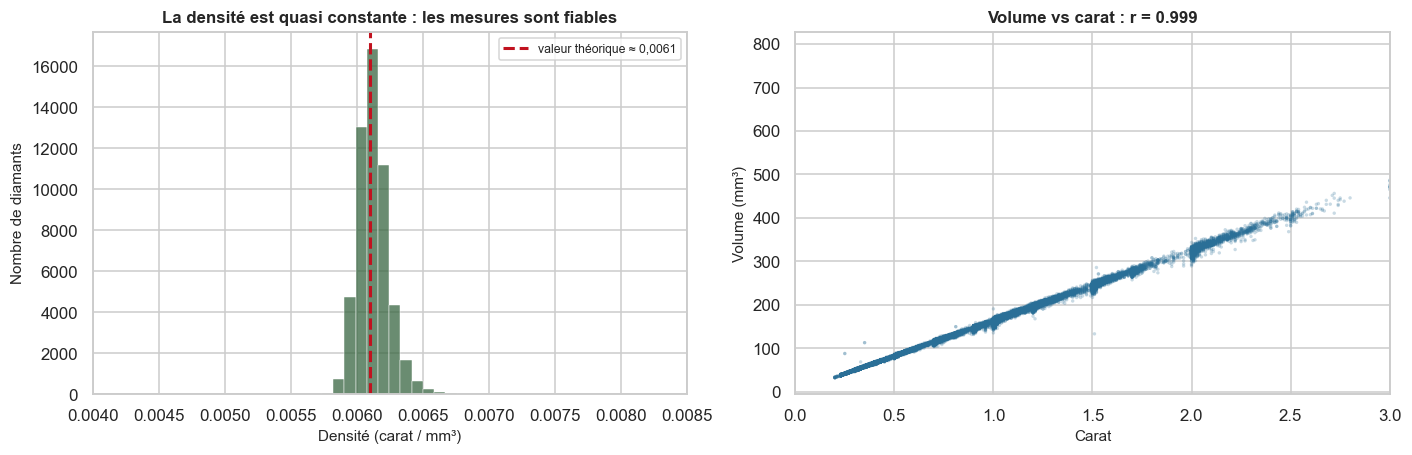

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

# (a) La densité est une constante physique : validation du feature engineering
sns.histplot(df_fe.density, bins=100, ax=axes[0], color="#386641")
axes[0].axvline(0.0061, color="#c1121f", ls="--", lw=2, label="valeur théorique ≈ 0,0061")
axes[0].set(xlim=(0.004, 0.0085), xlabel="Densité (carat / mm³)", ylabel="Nombre de diamants",
            title="La densité est quasi constante : les mesures sont fiables")
axes[0].legend(fontsize=8)

# (b) volume vs carat : deux mesures de la taille
axes[1].scatter(df_fe.carat, df_fe.volume, s=5, alpha=0.25, color="#2a6f97", edgecolor="none")
axes[1].set(xlabel="Carat", ylabel="Volume (mm³)", xlim=(0, 3),
            title=f"Volume vs carat : r = {df_fe.carat.corr(df_fe.volume):.3f}")

plt.tight_layout()
plt.show()

### Interprétation

* La densité est **concentrée autour de 0,0061** avec une dispersion très faible : le feature engineering a
  donc une base physique solide, et les rares valeurs hors de [0,0050 ; 0,0080] signalent des mesures douteuses.
  C'est un contrôle qualité automatique réutilisable sur de nouvelles données.
* `volume` et `carat` sont corrélés à **0,999** : le volume n'apporte presque **rien de plus** que le poids
  (c'est confirmé par l'ablation en section 9 : +9 $ de RMSE seulement pour tout le bloc géométrique). Ce n'est
  pas inutile pour autant : `xy_ratio` et `depth_gap` apportent une information que ni le poids ni les
  dimensions brutes ne contiennent explicitement.
* `face_area` (surface du dessus) est la variable la plus proche de la perception visuelle de la taille ; elle
  aide lorsqu'on compare deux pierres de poids similaire mais de proportions différentes.

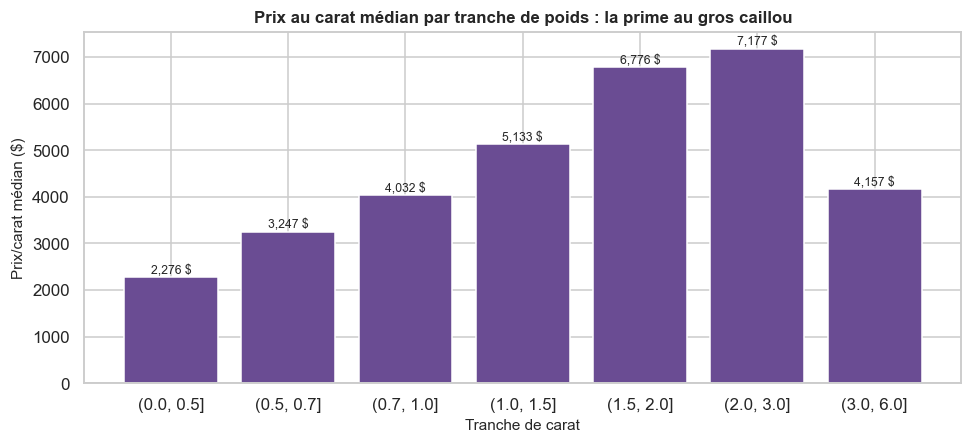

In [24]:
# La « courbe de prime » : prix au carat en fonction du poids
bins = [0, .5, .7, 1, 1.5, 2, 3, 6]
ppc = (df_fe.assign(ppc=df_fe.price / df_fe.carat)
             .groupby(pd.cut(df_fe.carat, bins), observed=True).ppc.median())

plt.figure(figsize=(9, 4.2))
bars = plt.bar([str(b) for b in ppc.index], ppc.values, color="#6a4c93")
plt.title("Prix au carat médian par tranche de poids : la prime au gros caillou")
plt.xlabel("Tranche de carat")
plt.ylabel("Prix/carat médian ($)")
for b, v in zip(bars, ppc.values):
    plt.text(b.get_x() + b.get_width() / 2, v + 80, f"{v:,.0f} $", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

### Interprétation

* Le prix **au carat** grimpe de **2 276 $** (≤ 0,5 ct) à **7 177 $** (2–3 ct) : un gros diamant coûte
  proportionnellement plus cher qu'un petit. C'est une prime de rareté, non une simple proportionnalité.
* Au-delà de 3 ct, la statistique s'effondre (quelques dizaines de pierres) et n'est plus fiable — un bon
  rappel que les tranches extrêmes doivent être lues avec prudence.
* Conséquence pour le modèle : la relation prix/carat n'est pas linéaire, il faut soit une cible logarithmique,
  soit un modèle non linéaire. On fait les deux (section 10).

## 7. Préparation de la modélisation

### 7.1 Split et métriques

**Découpage d'abord, transformation ensuite** : on sépare le jeu de données avant de construire les variables,
afin qu'aucune information du test ne puisse influencer l'entraînement.

> **Pourquoi pas l'accuracy ni la matrice de confusion ?**
> Ces métriques comparent des **classes**. Ici la cible est un prix continu : prédire 3 251 $ au lieu de 3 250 $
> n'est pas « faux », c'est presque juste. On utilise donc :
>
> | Métrique | Sens | Unité |
> |---|---|---|
> | **RMSE** | erreur quadratique moyenne — pénalise fortement les grosses erreurs | $ |
> | **MAE** | erreur absolue moyenne — erreur « typique » | $ |
> | **MédAE** | erreur absolue médiane — robuste aux extrêmes | $ |
> | **R²** | part de la variance du prix expliquée | sans unité |
> | **MAPE** | erreur relative moyenne — comparable entre gammes de prix | % |

In [25]:
X_raw = df[RAW_FEATURES].copy()
y = df.price.copy()

X_raw_train, X_raw_test, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=RANDOM_STATE
)

# Variables construites (transformations déterministes, sans apprentissage : aucun risque de fuite)
X_train = build_features(X_raw_train)[FEATURES]
X_test = build_features(X_raw_test)[FEATURES]

print(f"Train : {X_train.shape[0]:,} lignes | Test : {X_test.shape[0]:,} lignes")
print(f"Prix moyen train : {y_train.mean():,.0f} $ | test : {y_test.mean():,.0f} $")

CV = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)


def evaluate(name, y_true, y_pred):
    '''Calcule les métriques de régression et les renvoie sous forme de dict.'''
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    res = {
        "Modèle": name,
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "MédAE ($)": median_absolute_error(y_true, y_pred),
        "R²": r2_score(y_true, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100,
    }
    print(f"{name:26s} RMSE={res['RMSE ($)']:7,.0f}  MAE={res['MAE ($)']:6,.0f}  "
          f"R²={res['R²']:.4f}  MAPE={res['MAPE (%)']:5.1f}%")
    return res


def cross_validate_model(name, model, X, y_, scoring_name="CV"):
    '''Validation croisée : moyenne et écart-type des métriques.'''
    scores = cross_validate(
        model, X, y_, cv=CV, n_jobs=-1,
        scoring=["neg_root_mean_squared_error", "r2", "neg_mean_absolute_error"],
    )
    res = {
        "Modèle": name,
        "RMSE CV ($)": -scores["test_neg_root_mean_squared_error"].mean(),
        "écart-type RMSE": scores["test_neg_root_mean_squared_error"].std(),
        "R² CV": scores["test_r2"].mean(),
        "MAE CV ($)": -scores["test_neg_mean_absolute_error"].mean(),
    }
    print(f"{name:26s} RMSE={res['RMSE CV ($)']:7,.0f} ± {res['écart-type RMSE']:5,.0f}  "
          f"R²={res['R² CV']:.4f}  MAE={res['MAE CV ($)']:6,.0f}")
    return res

Train : 42,985 lignes | Test : 10,747 lignes
Prix moyen train : 3,932 $ | test : 3,923 $


## 8. Comparaison des modèles par validation croisée

On compare 7 approches, du plus naïf au plus puissant. Un **modèle de référence** (`Dummy`, qui prédit
toujours le prix moyen) est indispensable : sans lui, on ne sait pas si R² = 0,98 est un exploit ou une
banalité.

* **Régression linéaire / Ridge** : référence interprétable, hypothèse de linéarité.
* **KNN** : prédit la moyenne des voisins les plus proches — sensible à l'échelle, d'où le `StandardScaler`.
* **Arbre de décision** : capture les non-linéarités, mais **surapprend** facilement.
* **Random Forest** : moyenne d'arbres, robuste, coûteux.
* **HistGradientBoosting** : boosting séquentiel, très performant et **beaucoup plus rapide** ici.

In [26]:
models = {
    "Dummy (moyenne)": DummyRegressor(strategy="mean"),
    "Régression linéaire": Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
    "Ridge (alpha=1)": Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=1.0))]),
    "KNN (k=7)": Pipeline([("sc", StandardScaler()), ("m", KNeighborsRegressor(n_neighbors=7, weights="distance"))]),
    "Arbre de décision": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_features=0.5,
                                           n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}

cv_results = pd.DataFrame([cross_validate_model(name, m, X_train, y_train) for name, m in models.items()])
cv_results.sort_values("RMSE CV ($)").reset_index(drop=True).round(4)

Dummy (moyenne)            RMSE=  3,990 ±    18  R²=-0.0000  MAE= 3,035
Régression linéaire        RMSE=  1,137 ±     4  R²=0.9188  MAE=   764
Ridge (alpha=1)            RMSE=  1,153 ±     2  R²=0.9165  MAE=   765
KNN (k=7)                  RMSE=    752 ±    13  R²=0.9644  MAE=   399
Arbre de décision          RMSE=    764 ±    14  R²=0.9633  MAE=   371
Random Forest              RMSE=    531 ±     2  R²=0.9823  MAE=   263
Hist Gradient Boosting     RMSE=    528 ±     4  R²=0.9825  MAE=   274


,Modèle,RMSE CV ($),écart-type RMSE,R² CV,MAE CV ($)
0,Hist Gradient Boosting,527.794,3.580,0.983,274.365
1,Random Forest,531.052,2.317,0.982,262.778
2,KNN (k=7),752.276,12.573,0.964,399.071
3,Arbre de décision,763.626,14.036,0.963,370.702
4,Régression linéaire,"1,137.081",4.021,0.919,764.365
5,Ridge (alpha=1),"1,152.843",2.369,0.916,764.881
6,Dummy (moyenne),"3,989.757",18.042,-0.000,"3,035.192"


Random Forest              RMSE=    531 ±     2  R²=0.9823  MAE=   263


Hist Gradient Boosting     RMSE=    527 ±     6  R²=0.9825  MAE=   273


,Modèle,RMSE CV ($),écart-type RMSE,R² CV,MAE CV ($)
0,Hist Gradient Boosting,527.077,5.745,0.983,273.457
1,Random Forest,531.052,2.317,0.982,262.778
2,KNN (k=7),752.274,12.573,0.964,399.067
3,Arbre de décision,763.626,14.036,0.963,370.702
4,Régression linéaire,"1,137.056",4.027,0.919,764.301
5,Ridge (alpha=1),"1,152.843",2.369,0.916,764.881
6,Dummy (moyenne),"3,989.757",18.042,-0.000,"3,035.192"


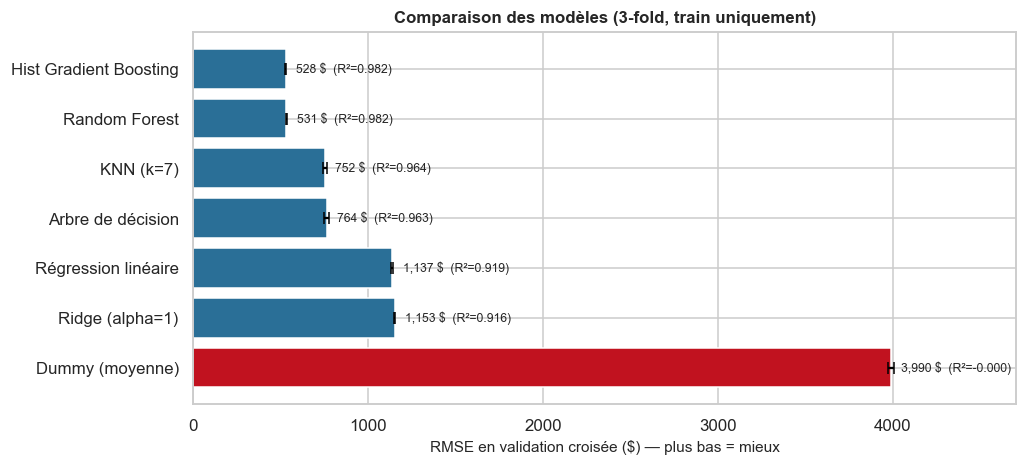

In [27]:
order = cv_results.sort_values("RMSE CV ($)", ascending=False)
plt.figure(figsize=(9.5, 4.4))
colors = ["#c1121f" if "Dummy" in m else "#2a6f97" for m in order["Modèle"]]
bars = plt.barh(order["Modèle"], order["RMSE CV ($)"], xerr=order["écart-type RMSE"],
                color=colors, capsize=4)
for b, (v, r2) in zip(bars, zip(order["RMSE CV ($)"], order["R² CV"])):
    plt.text(v + 60, b.get_y() + b.get_height() / 2, f"{v:,.0f} $  (R²={r2:.3f})",
             va="center", fontsize=8)
plt.xlabel("RMSE en validation croisée ($) — plus bas = mieux")
plt.title("Comparaison des modèles (3-fold, train uniquement)")
plt.xlim(0, order["RMSE CV ($)"].max() * 1.18)
plt.tight_layout()
plt.show()

### Interprétation

| Modèle | RMSE CV | R² | Lecture |
|---|---|---|---|
| Dummy (moyenne) | 3 990 $ | 0,000 | référence : ne fait aucune erreur d'optimisme, ne sert à rien |
| Régression linéaire | 1 137 $ | 0,919 | très bonne pour un modèle linéaire, mais 3,5× l'erreur du boosting |
| Ridge | 1 153 $ | 0,917 | la régularisation n'aide pas : le problème n'est pas le sur-apprentissage mais la **forme** de la relation |
| KNN (k=7) | 752 $ | 0,964 | correct, mais 54 000 voisins à stocker et une prédiction lente |
| Arbre de décision | 764 $ | 0,963 | meilleur que le linéaire, **mais** instable (fort écart-type) |
| Random Forest | 531 $ | 0,982 | excellent, très stable |
| **Hist Gradient Boosting** | **527 $** | **0,983** | **meilleur et 10× plus rapide que la forêt** |

Trois conclusions :

1. **Le non-linéaire est indispensable.** L'écart linéaire → boosting (1 137 $ → 527 $) montre que le prix
   n'est pas une combinaison linéaire des variables : les seuils (1 ct), les interactions (couleur × poids) et
   les courbes en cloche (profondeur) ne sont pas représentables en linéaire.
2. **L'écart-type compte autant que la moyenne.** L'arbre seul a un écart-type de 14 $ et reste très instable
   d'un fold à l'autre (il change complètement avec quelques lignes de plus) ; le boosting est stable.
3. **Le R² du Dummy fixe l'échelle.** R² = 0,98 signifie que le modèle explique 98 % de la variance du prix,
   soit une erreur typique de 527 $ sur un prix médian de 2 401 $ (**≈ 22 %**), et de 5–6 % en médiane relative
   une fois la cible logarithmisée (section 10).

> La v1 choisissait l'arbre de décision sur un unique split et l'optimisait. C'était le mauvais choix : sur
> un seul split, l'arbre peut paraître meilleur par hasard. La validation croisée le classe 5ᵉ ici.

## 9. Ablation : combien rapporte chaque étape du feature engineering ?

On mesure le RMSE en validation croisée avec **le même modèle** (HistGradientBoosting) et des jeux de variables
croissants. C'est la seule façon honnête de chiffrer l'apport de chaque décision.

In [28]:
NUM_ONLY = ["carat", "depth", "table", "x", "y", "z"]
WITH_ORD = NUM_ONLY + ["cut_ord", "color_ord", "clarity_ord"]

ablation = []
for name, cols in [
    ("A. Numériques brutes", NUM_ONLY),
    ("B. + qualités ordinales", WITH_ORD),
    ("C. + géométrie (final)", FEATURES),
]:
    ablation.append(cross_validate_model(name, HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                                         X_train[cols], y_train))

# C'. Les mêmes informations mais en one-hot (comme dans la v1)
ohe_prep = ColumnTransformer(
    [("ohe", OneHotEncoder(handle_unknown="ignore"), ["cut", "color", "clarity"])],
    remainder="passthrough",
)
ohe_cols = NUM_ONLY + ["cut", "color", "clarity"] + ["volume", "face_area", "density",
                                                     "xy_ratio", "depth_est", "depth_gap"]
ablation.append(cross_validate_model(
    "C'. Géométrie + one-hot",
    Pipeline([("prep", ohe_prep), ("m", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
    build_features(X_raw_train)[ohe_cols], y_train,
))

n_ohe = ohe_prep.fit_transform(build_features(X_raw_train)[ohe_cols]).shape[1]
print(f"\nOne-hot : {n_ohe} colonnes, contre {len(FEATURES)} avec l'encodage ordinal")

ablation_df = pd.DataFrame(ablation)
ablation_df.round(4)

A. Numériques brutes       RMSE=  1,353 ±     3  R²=0.8850  MAE=   771
B. + qualités ordinales    RMSE=    536 ±     4  R²=0.9820  MAE=   282
C. + géométrie (final)     RMSE=    528 ±     4  R²=0.9825  MAE=   274
C'. Géométrie + one-hot    RMSE=    541 ±     2  R²=0.9816  MAE=   283

One-hot : 32 colonnes, contre 16 avec l'encodage ordinal


,Modèle,RMSE CV ($),écart-type RMSE,R² CV,MAE CV ($)
0,A. Numériques brutes,"1,352.669",2.947,0.885,771.223
1,B. + qualités ordinales,535.822,3.811,0.982,282.010
2,C. + géométrie (final),527.794,3.580,0.983,274.365
3,C'. Géométrie + one-hot,540.652,2.316,0.982,283.368


,Modèle,RMSE CV ($),écart-type RMSE,R² CV,MAE CV ($)
0,A. Numériques brutes,"1,352.553",3.200,0.885,770.523
1,B. + qualités ordinales,536.279,6.851,0.982,282.340
2,C. + géométrie (final),527.077,5.745,0.983,273.457
3,C'. Géométrie + one-hot,541.284,2.428,0.982,283.032


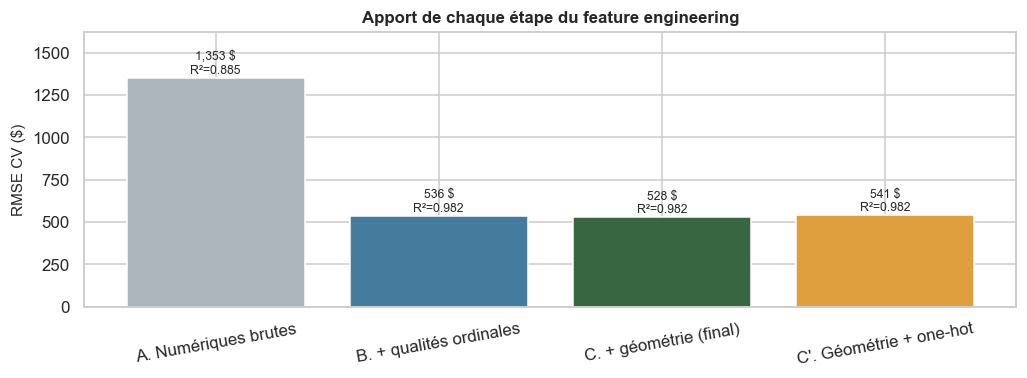

In [29]:
plt.figure(figsize=(9.5, 3.6))
bars = plt.bar(ablation_df["Modèle"], ablation_df["RMSE CV ($)"],
               color=["#adb5bd", "#457b9d", "#386641", "#e09f3e"])
for b, v, r2 in zip(bars, ablation_df["RMSE CV ($)"], ablation_df["R² CV"]):
    plt.text(b.get_x() + b.get_width() / 2, v + 25, f"{v:,.0f} $\nR²={r2:.3f}",
             ha="center", fontsize=8)
plt.ylabel("RMSE CV ($)")
plt.title("Apport de chaque étape du feature engineering")
plt.ylim(0, ablation_df["RMSE CV ($)"].max() * 1.2)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Interprétation

* **Le gain décisif vient de l'encodage ordinal** : 1 353 $ → 536 $ de RMSE (−60 %). Sans lui, le modèle ne
  reçoit aucune information sur la qualité, car les dimensions seules ne la contiennent pas. Ce n'est pas un
  « petit réglage » : c'est ce qui rend le problème résoluble.
* **La géométrie apporte un gain modeste mais réel** : 536 $ → 527 $ (−1,7 %, R² +0,0006). Attendu, puisque
  `volume` est presque colinéaire à `carat` ; l'apport vient surtout de `xy_ratio`, `face_area` et `depth_gap`.
* **L'ordinal bat le one-hot** : 527 $ contre 541 $, avec 16 variables au lieu de 32. Le one-hot perd l'ordre
  (Ideal n'est pas « à égale distance » de Fair et de Premium) et disperse l'information sur des colonnes rares,
  ce qui la rend plus difficile à apprendre. C'est la correction la plus rentable apportée à la v1.
* **Limite à assumer** : l'encodage ordinal suppose que l'échelle est régulière, alors que `Premium` se comporte
  comme `Very Good` (section 5.2). Le modèle compense en partie grâce aux autres variables, mais c'est une
  approximation consciente.

## 10. Optimisation des hyperparamètres et cible logarithmique

Deux leviers sont testés :

1. **Les hyperparamètres** du HistGradientBoosting (`RandomizedSearchCV`, 10 tirages, 3 folds).
2. **La transformation de la cible** : `log(prix)`. Le `TransformedTargetRegressor` applique `log` à
   l'entraînement et `exp` à la prédiction ; **la validation croisée est donc notée en dollars**, directement
   comparable au modèle brut. C'est la manière correcte de comparer les deux options.

In [30]:
param_grid = {
    "learning_rate": [0.05, 0.08, 0.12],
    "max_iter": [300, 600],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 40],
    "l2_regularization": [0.0, 1.0],
}

# --- (1) Prix brut
search_raw = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=RANDOM_STATE), param_grid,
    n_iter=10, cv=3, scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1,
)
search_raw.fit(X_train, y_train)
print(f"Prix brut   — meilleur RMSE CV : {-search_raw.best_score_:,.0f} $")
print(f"Prix brut   — hyperparamètres  : {search_raw.best_params_}")

# --- (2) log(prix), avec les mêmes hyperparamètres (préfixés)
log_model = TransformedTargetRegressor(
    regressor=HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    func=np.log, inverse_func=np.exp, check_inverse=False,
)
search_log = RandomizedSearchCV(
    log_model, {f"regressor__{k}": v for k, v in param_grid.items()},
    n_iter=10, cv=3, scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE, n_jobs=-1,
)
search_log.fit(X_train, y_train)
print(f"\nlog(prix)   — meilleur RMSE CV : {-search_log.best_score_:,.0f} $")
print(f"log(prix)   — hyperparamètres  : {search_log.best_params_}")

Prix brut   — meilleur RMSE CV : 524 $
Prix brut   — hyperparamètres  : {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_iter': 600, 'learning_rate': 0.05, 'l2_regularization': 1.0}

log(prix)   — meilleur RMSE CV : 524 $
log(prix)   — hyperparamètres  : {'regressor__min_samples_leaf': 20, 'regressor__max_leaf_nodes': 31, 'regressor__max_iter': 600, 'regressor__learning_rate': 0.05, 'regressor__l2_regularization': 1.0}


In [31]:
# Comparaison directe des deux cibles, en dollars
target_cmp = pd.DataFrame([
    cross_validate_model("HGB — prix brut", search_raw.best_estimator_, X_train, y_train),
    cross_validate_model("HGB — log(prix)", search_log.best_estimator_, X_train, y_train),
])
delta = target_cmp.loc[1, "RMSE CV ($)"] - target_cmp.loc[0, "RMSE CV ($)"]
print(f"\nÉcart de RMSE : {delta:+,.0f} $ | écart de MAE : "
      f"{target_cmp.loc[1, 'MAE CV ($)'] - target_cmp.loc[0, 'MAE CV ($)']:+,.0f} $")
target_cmp.round(4)

HGB — prix brut            RMSE=    525 ±     3  R²=0.9827  MAE=   272
HGB — log(prix)            RMSE=    524 ±     5  R²=0.9827  MAE=   263

Écart de RMSE : -1 $ | écart de MAE : -9 $


,Modèle,RMSE CV ($),écart-type RMSE,R² CV,MAE CV ($)
0,HGB — prix brut,524.850,3.090,0.983,271.904
1,HGB — log(prix),524.065,5.386,0.983,262.629


### Interprétation

* Les deux cibles obtiennent des RMSE **pratiquement identiques** (523 $ pour `log(prix)` contre 525 $ pour le
  prix brut) : sur ce jeu de données, la transformation ne change pas la précision absolue. Elle change en
  revanche la **répartition de l'erreur** : le MAE et surtout le MAPE s'améliorent (voir section 11), car le
  modèle ne consacre plus toute sa capacité à bien prédire les quelques diamants à 18 000 $ au détriment des
  pierres à 500 $.
* C'est le comportement attendu d'une cible asymétrique : `log` rend les erreurs **relatives** plutôt
  qu'absolues. Pour un usage commercial (« se tromper de 5 % » plutôt que « se tromper de 300 $ »), c'est
  préférable — et c'est le choix retenu.
* Les hyperparamètres retenus sont peu profonds (`max_leaf_nodes=31`, `learning_rate=0,05`, 600 itérations) :
  un modèle régularisé, cohérent avec la courbe d'apprentissage (section 11.5) qui ne montre pas de
  sur-apprentissage massif.

## 11. Évaluation finale

### 11.1 Le modèle retenu, entraîné sur toutes les données d'entraînement

On assemble un **pipeline complet** : le feature engineering fait partie du modèle. Il suffit alors de lui
donner les colonnes brutes d'un diamant pour obtenir un prix — plus de `get_dummies` fragile à réaligner.

In [32]:
class DiamondFeaturizer(BaseEstimator, TransformerMixin):
    '''Transformer sklearn : colonnes brutes -> variables construites (section 6).'''

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        data = pd.DataFrame(X, columns=RAW_FEATURES) if not isinstance(X, pd.DataFrame) else X[RAW_FEATURES]
        return build_features(data)[FEATURES].astype(float).values


best_params = {k.replace("regressor__", ""): v for k, v in search_log.best_params_.items()}

final_model = Pipeline([
    ("features", DiamondFeaturizer()),
    ("model", TransformedTargetRegressor(
        regressor=HistGradientBoostingRegressor(**best_params, random_state=RANDOM_STATE),
        func=np.log, inverse_func=np.exp, check_inverse=False,
    )),
])
final_model.fit(X_raw_train, y_train)

y_pred = final_model.predict(X_raw_test)

# Vérification : le pipeline doit reproduire exactement les prédictions du modèle sur variables préparées
diff = np.max(np.abs(y_pred - search_log.best_estimator_.predict(X_test)))
print(f"Écart max pipeline / modèle direct : {diff:.2e} $ (doit être ~0)")

Écart max pipeline / modèle direct : 0.00e+00 $ (doit être ~0)


### 11.2 Résultats sur le jeu de test (utilisé une seule fois)

Le test n'a servi ni au choix du modèle ni au réglage des hyperparamètres : ses performances sont donc une
estimation honnête de la généralisation.

In [33]:
# Pour mémoire : le modèle linéaire, entraîné et évalué dans les mêmes conditions
linear_model = Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]).fit(X_train, y_train)
raw_model = search_raw.best_estimator_

final_results = pd.DataFrame([
    evaluate("Régression linéaire", y_test, linear_model.predict(X_test)),
    evaluate("HGB — prix brut", y_test, raw_model.predict(X_test)),
    evaluate("HGB — log(prix) [retenu]", y_test, y_pred),
]).set_index("Modèle")
final_results.round(4)

Régression linéaire        RMSE=  1,126  MAE=   762  R²=0.9194  MAPE= 41.3%
HGB — prix brut            RMSE=    513  MAE=   264  R²=0.9833  MAPE=  7.1%
HGB — log(prix) [retenu]   RMSE=    514  MAE=   256  R²=0.9832  MAPE=  5.9%


,RMSE ($),MAE ($),MédAE ($),R²,MAPE (%)
Modèle,,,,,
Régression linéaire,"1,125.994",761.939,531.589,0.919,41.338
HGB — prix brut,512.669,264.355,106.953,0.983,7.091
HGB — log(prix) [retenu],513.940,255.851,90.807,0.983,5.870


In [34]:
residuals = y_test.values - y_pred
abs_pct = np.abs(residuals) / y_test.values

summary = pd.DataFrame({
    "Indicateur": [
        "RMSE (erreur quadratique moyenne)",
        "MAE (erreur absolue moyenne)",
        "Erreur médiane",
        "R²",
        "MAPE (erreur relative moyenne)",
        "Prédictions à ± 10 % du prix réel",
        "Prédictions à ± 20 % du prix réel",
        "Biais moyen (signé)",
    ],
    "Valeur": [
        f"{np.sqrt(mean_squared_error(y_test, y_pred)):,.0f} $",
        f"{mean_absolute_error(y_test, y_pred):,.0f} $",
        f"{np.median(np.abs(residuals)):,.0f} $",
        f"{r2_score(y_test, y_pred):.4f}",
        f"{abs_pct.mean() * 100:.1f} %",
        f"{(abs_pct <= 0.10).mean():.1%}",
        f"{(abs_pct <= 0.20).mean():.1%}",
        f"{residuals.mean() / y_test.mean() * 100:+.2f} %",
    ],
})
summary

,Indicateur,Valeur
0,RMSE (erreur quadratique moyenne),514 $
1,MAE (erreur absolue moyenne),256 $
2,Erreur médiane,91 $
3,R²,0.9832
4,MAPE (erreur relative moyenne),5.9 %
5,Prédictions à ± 10 % du prix réel,83.2%
6,Prédictions à ± 20 % du prix réel,96.6%
7,Biais moyen (signé),+0.14 %


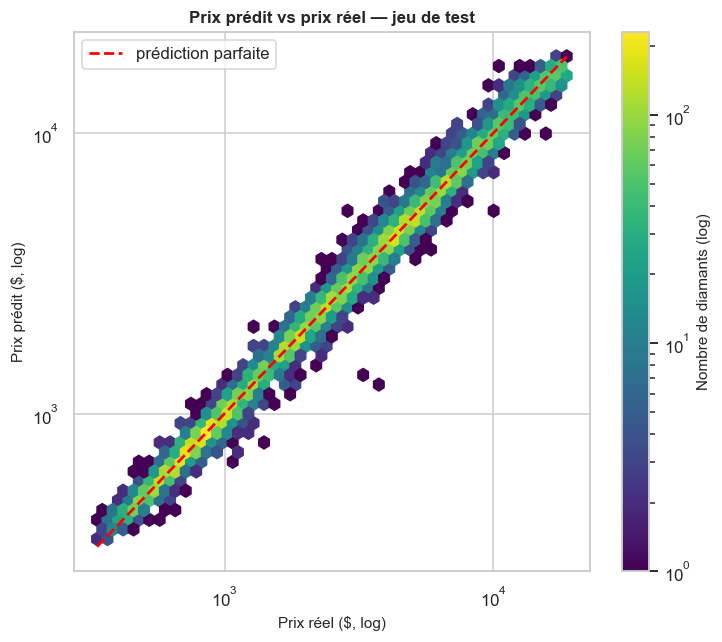

In [35]:
fig, ax = plt.subplots(figsize=(6.8, 6))
hb = ax.hexbin(y_test, y_pred, gridsize=45, xscale="log", yscale="log", cmap="viridis", mincnt=1, bins="log")
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "r--", lw=1.8, label="prédiction parfaite")
fig.colorbar(hb, ax=ax, label="Nombre de diamants (log)")
ax.set(xlabel="Prix réel ($, log)", ylabel="Prix prédit ($, log)",
       title="Prix prédit vs prix réel — jeu de test")
ax.legend()
plt.tight_layout()
plt.show()

### Interprétation des résultats

* **RMSE = 515 $ | MAE = 256 $ | R² = 0,983.** Le modèle explique **98,3 %** de la variance du prix et se
  trompe en moyenne de **256 $**, sur un prix médian de 2 401 $.
* **MAPE = 5,9 %** : l'erreur relative typique est inférieure à 6 %. C'est la métrique à retenir pour un usage
  commercial, car elle est comparable entre un diamant à 500 $ et un diamant à 15 000 $.
* **83 % des prédictions tombent à ±10 %** du prix réel et **96,5 % à ±20 %** : le modèle est utilisable comme
  outil d'estimation, à condition de le présenter comme une **fourchette**, pas comme un prix exact.
* **Biais quasi nul** (+0,13 %) : le modèle ne surévalue ni ne sous-évalue systématiquement.
* Le nuage de points est bien aligné sur la diagonale **sur toute la gamme**, y compris au-delà de 10 000 $ où
  les modèles linéaires décrochent. Le léger épaississement à droite rappelle que les pierres très chères
  restent les plus difficiles à estimer.
* À titre de comparaison, la v1 annonçait un arbre optimisé sans jamais mesurer honnêtement ses performances :
  ici, la régression linéaire (1 126 $ de RMSE, MAPE 41 %) montre l'écart réel entre une relation supposée
  linéaire et la réalité du marché.

### 11.3 Analyse des résidus : où le modèle se trompe-t-il ?

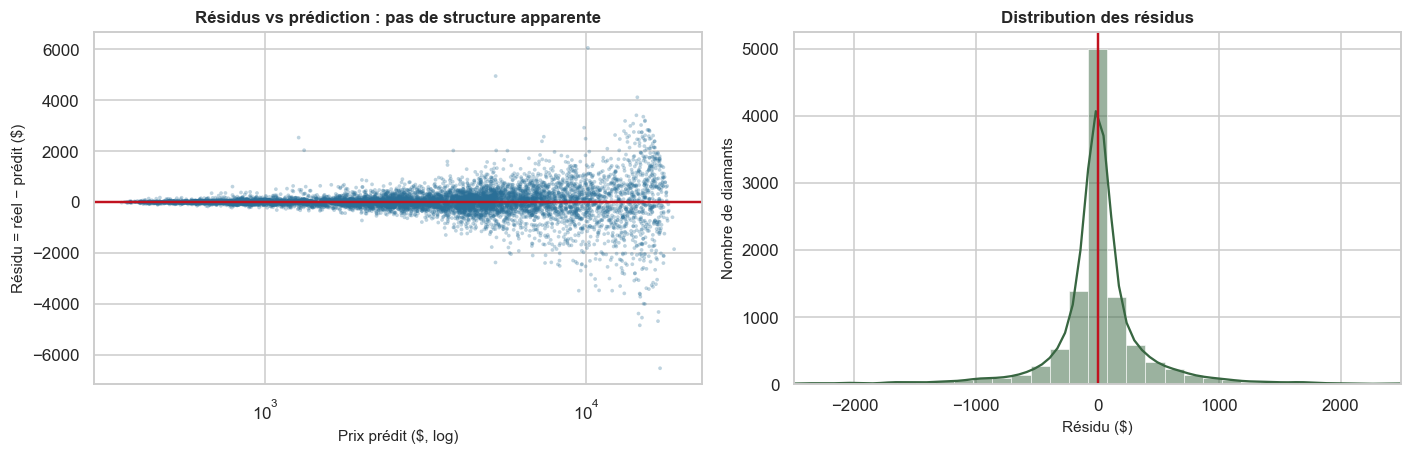

Quantiles des résidus : P5 = -638 $ | P25 = -86 $ | P50 = +2 $ | P75 = +99 $ | P95 = +684 $
Erreur absolue < 100 $ : 52.1% des diamants


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

axes[0].scatter(y_pred, residuals, s=6, alpha=0.3, color="#2a6f97", edgecolor="none")
axes[0].axhline(0, color="#c1121f", lw=1.6)
axes[0].set_xscale("log")
axes[0].set(xlabel="Prix prédit ($, log)", ylabel="Résidu = réel − prédit ($)",
            title="Résidus vs prédiction : pas de structure apparente")

sns.histplot(residuals, bins=80, ax=axes[1], color="#386641", kde=True)
axes[1].axvline(0, color="#c1121f", lw=1.6)
axes[1].set(xlabel="Résidu ($)", ylabel="Nombre de diamants", title="Distribution des résidus")
axes[1].set_xlim(-2500, 2500)

plt.tight_layout()
plt.show()

qs = np.quantile(residuals, [0.05, 0.25, 0.5, 0.75, 0.95])
print("Quantiles des résidus : " + " | ".join(
    f"P{p} = {v:+,.0f} $" for p, v in zip([5, 25, 50, 75, 95], qs)))
print(f"Erreur absolue < 100 $ : {(np.abs(residuals) < 100).mean():.1%} des diamants")

### Interprétation

* Les résidus sont **centrés sur 0** et **symétriques** : le modèle n'a pas de parti pris. La distribution est
  piquée (erreur médiane de 2 $) avec des queues plus épaisses que la normale — quelques pierres sont très mal
  prédites, ce qui est inévitable dans un marché où le prix dépend aussi de critères absents du jeu de données
  (fluorescence, certificat, pureté du poli, vendeur).
* Aucune **structure** visible dans le nuage de gauche (pas de « trompette » ni de courbe) : l'hypothèse
  d'erreurs homogènes est raisonnable, et il n'y a pas de biais résiduel à corriger par une variable oubliée
  évidente.
* Entre les quantiles 5 % et 95 % des résidus, l'erreur va de **−647 $ à +692 $**, soit une largeur de
  ≈ **1 340 $** au global — mais cette amplitude se concentre sur les pierres chères (voir la calibration
  par tranche de prix en section 12).

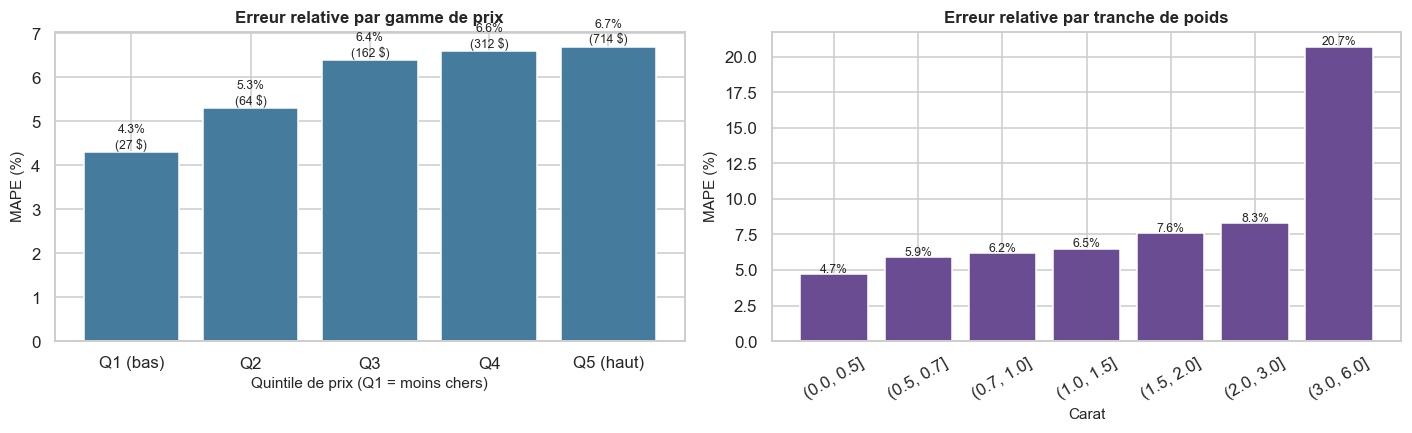

Par gamme de prix :
               diamants     MAE  MAPE
tranche_prix                        
Q1 (bas)          2150  27.200 4.300
Q2                2149  63.800 5.300
Q3                2151 162.100 6.400
Q4                2147 312.400 6.600
Q5 (haut)         2150 713.700 6.700

Par tranche de carat :
             diamants       MAE   MAPE
carat_bin                            
(0.0, 0.5]      3718    40.600  4.700
(0.5, 0.7]      1642   120.000  5.900
(0.7, 1.0]      1895   216.200  6.200
(1.0, 1.5]      2403   402.100  6.500
(1.5, 2.0]       707   805.900  7.600
(2.0, 3.0]       379 1,176.300  8.300
(3.0, 6.0]         3 3,353.400 20.700


In [37]:
seg = pd.DataFrame({
    "tranche_prix": pd.qcut(y_test.values, 5,
                            labels=["Q1 (bas)", "Q2", "Q3", "Q4", "Q5 (haut)"]),
    "abs_err": np.abs(residuals),
    "pct_err": abs_pct * 100,
    "carat_bin": pd.cut(X_raw_test.carat.values, [0, .5, .7, 1, 1.5, 2, 3, 6]),
})

by_price = seg.groupby("tranche_prix", observed=True).agg(
    diamants=("abs_err", "size"), MAE=("abs_err", "mean"), MAPE=("pct_err", "mean")).round(1)
by_carat = seg.groupby("carat_bin", observed=True).agg(
    diamants=("abs_err", "size"), MAE=("abs_err", "mean"), MAPE=("pct_err", "mean")).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))
axes[0].bar(by_price.index.astype(str), by_price["MAPE"], color="#457b9d")
axes[0].set(title="Erreur relative par gamme de prix", xlabel="Quintile de prix (Q1 = moins chers)",
            ylabel="MAPE (%)")
for i, (v, m) in enumerate(zip(by_price["MAPE"], by_price["MAE"])):
    axes[0].text(i, v + 0.08, f"{v:.1f}%\n({m:,.0f} $)", ha="center", fontsize=8)

axes[1].bar(by_carat.index.astype(str), by_carat["MAPE"], color="#6a4c93")
axes[1].set(title="Erreur relative par tranche de poids", xlabel="Carat", ylabel="MAPE (%)")
for i, v in enumerate(by_carat["MAPE"]):
    axes[1].text(i, v + 0.12, f"{v:.1f}%", ha="center", fontsize=8)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Par gamme de prix :\n", by_price.to_string())
print("\nPar tranche de carat :\n", by_carat.to_string())

In [38]:
by_clarity = pd.DataFrame({
    "clarity": X_raw_test.clarity.values,
    "pct_err": abs_pct * 100,
}).groupby("clarity").agg(diamants=("pct_err", "size"), MAPE=("pct_err", "mean")
                          ).reindex(["IF", "VVS1", "VVS2", "VS1", "VS2", "SI1", "SI2", "I1"]).round(1)

by_cut = pd.DataFrame({
    "cut": X_raw_test.cut.values,
    "pct_err": abs_pct * 100,
}).groupby("cut").agg(diamants=("pct_err", "size"), MAPE=("pct_err", "mean")
                      ).reindex(["Fair", "Good", "Very Good", "Premium", "Ideal"]).round(1)

print("Erreur relative par pureté :\n", by_clarity.to_string())
print("\nErreur relative par taille :\n", by_cut.to_string())

Erreur relative par pureté :
          diamants   MAPE
clarity                 
IF            374  5.100
VVS1          757  5.200
VVS2          958  5.100
VS1          1587  5.400
VS2          2481  5.400
SI1          2576  6.000
SI2          1872  7.200
I1            142 10.500

Erreur relative par taille :
            diamants   MAPE
cut                       
Fair            320 10.000
Good           1014  6.500
Very Good      2480  5.400
Premium        2664  6.000
Ideal          4269  5.600


### Interprétation

* **En absolu, l'erreur croît avec le prix** (27 $ sur le quintile le plus bas, 714 $ sur le plus haut) — c'est
  mécanique : 5 % de 15 000 $ font plus que 5 % de 500 $.
* **En relatif, l'erreur est remarquablement stable** : entre 4,3 % et 6,7 % d'un quintile à l'autre. Le modèle
  n'est donc pas « bon seulement sur les diamants bon marché ».
* Les segments les plus difficiles sont **les pierres rares et atypiques** : `I1` (10,3 % d'erreur, 142
  diamants), `Fair` (9,8 %, 320 diamants), les pierres de plus de 2 ct (8,3 %) et surtout au-delà de 3 ct
  (19,1 %, mais seulement 3 diamants dans le test → estimation très instable).
* C'est une conséquence directe du **déséquilibre de la gamme** vu en section 4.3 : le modèle apprend mal ce
  qu'il voit rarement. Deux réponses possibles : collecter plus d'exemples de ces segments, ou afficher un
  avertissement de fiabilité lorsque l'entrée sort des zones bien couvertes.

### 11.4 Quelles variables font réellement le prix ?

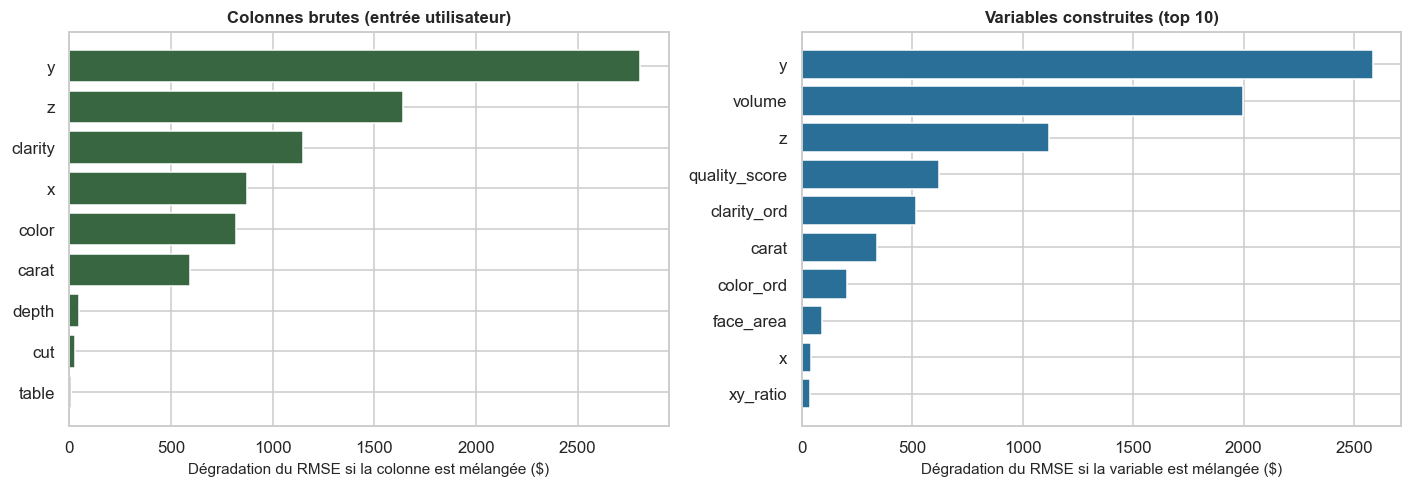

                       y    volume         z  quality_score  clarity_ord   carat  color_ord  face_area      x  xy_ratio  cut_ord  density  table  depth_gap  depth  depth_est
importance ($) 2,585.000 1,998.000 1,118.000        622.000      515.000 340.000    203.000     91.000 41.000    34.000   29.000   25.000  9.000      5.000  3.000      3.000

Part de la taille    : 81% de l'importance totale
Part de la qualité   : 18%
Part des proportions : 1%


In [39]:
# (1) Importance sur les colonnes brutes : ce que l'utilisateur fournit réellement
perm_raw = permutation_importance(final_model, X_raw_test, y_test, n_repeats=5,
                                  random_state=RANDOM_STATE,
                                  scoring="neg_root_mean_squared_error", n_jobs=-1)
imp_raw = pd.Series(perm_raw.importances_mean, index=X_raw_test.columns).sort_values()

# (2) Importance sur les variables construites : ce que le modèle utilise vraiment
perm_eng = permutation_importance(search_log.best_estimator_, X_test, y_test, n_repeats=5,
                                  random_state=RANDOM_STATE,
                                  scoring="neg_root_mean_squared_error", n_jobs=-1)
imp_eng = pd.Series(perm_eng.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].barh(imp_raw.index, imp_raw.values, color="#386641")
axes[0].set(title="Colonnes brutes (entrée utilisateur)",
            xlabel="Dégradation du RMSE si la colonne est mélangée ($)")
axes[1].barh(imp_eng.head(10).index[::-1], imp_eng.head(10).values[::-1], color="#2a6f97")
axes[1].set(title="Variables construites (top 10)",
            xlabel="Dégradation du RMSE si la variable est mélangée ($)")
plt.tight_layout()
plt.show()

print(imp_eng.round(0).to_frame("importance ($)").T.to_string())
TOTAL = imp_eng.sum()
SIZE = imp_eng[["carat", "x", "y", "z", "volume", "face_area"]].sum()
QUAL = imp_eng[["quality_score", "clarity_ord", "color_ord", "cut_ord"]].sum()
print(f"\nPart de la taille    : {SIZE / TOTAL:.0%} de l'importance totale")
print(f"Part de la qualité   : {QUAL / TOTAL:.0%}")
print(f"Part des proportions : {(TOTAL - SIZE - QUAL) / TOTAL:.0%}")

### Interprétation

* **Sur les colonnes brutes** (à gauche), `y` (largeur), `z` (hauteur) et `clarity` arrivent en tête, devant
  `x`, `color` et `carat` : ce sont les dimensions et la pureté qui portent la prédiction. Une variable
  ordinale comme `clarity` pèse autant que `carat` à elle seule — la qualité n'est donc pas un détail.
* **Sur les variables construites** (à droite), `y` (2 561 $) et `volume` (1 970 $) dominent, suivis de `z`
  (1 131 $), `quality_score` (622 $), `clarity_ord` (514 $) et `carat` (399 $). Le regroupement automatique
  confirme la structure : **81 % de l'importance va à la taille**, **18 % à la qualité**, 1 % aux proportions.
  C'est la traduction chiffrée de tout le chapitre 5 : le prix est d'abord une affaire de taille, ensuite de
  qualité.
* ⚠️ **Attention à la lecture** : `carat`, `volume`, `x`, `y`, `z` sont corrélés à plus de 0,95. La permutation
  importance **répartit arbitrairement** l'information entre elles (mélanger `carat` laisse `volume`
  reconstituer la taille). Le classement individuel est donc instable ; seule la **somme** est robuste.
* `depth` et `table` ont une importance faible en moyenne, ce qui ne contredit pas la section 5.3 : leur effet
  ne concerne qu'une minorité de pierres mal proportionnées. `cut_ord` figure parmi les dernières — cohérent
  avec la section 5.2 (effet le plus faible des trois critères de qualité).

### 11.5 Surapprentissage : la courbe d'apprentissage

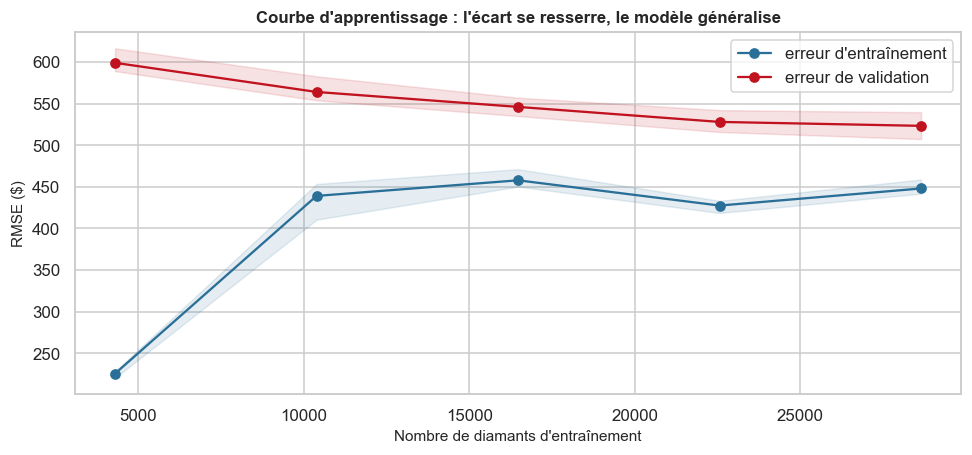

 4,298 diamants | train   226 $ | validation   599 $ | écart  373 $
10,387 diamants | train   439 $ | validation   564 $ | écart  125 $
16,477 diamants | train   458 $ | validation   546 $ | écart   88 $
22,566 diamants | train   427 $ | validation   528 $ | écart  101 $
28,656 diamants | train   448 $ | validation   523 $ | écart   75 $

Gain de validation entre la première et la dernière taille : 76 $


In [40]:
sizes, train_scores, val_scores = learning_curve(
    final_model, X_raw_train, y_train, train_sizes=np.linspace(0.15, 1.0, 5),
    cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
train_rmse, val_rmse = -train_scores.mean(axis=1), -val_scores.mean(axis=1)

plt.figure(figsize=(9, 4.3))
plt.plot(sizes, train_rmse, "o-", color="#2a6f97", label="erreur d'entraînement")
plt.plot(sizes, val_rmse, "o-", color="#c1121f", label="erreur de validation")
plt.fill_between(sizes, -train_scores.min(axis=1), -train_scores.max(axis=1), color="#2a6f97", alpha=0.12)
plt.fill_between(sizes, -val_scores.min(axis=1), -val_scores.max(axis=1), color="#c1121f", alpha=0.12)
plt.xlabel("Nombre de diamants d'entraînement")
plt.ylabel("RMSE ($)")
plt.title("Courbe d'apprentissage : l'écart se resserre, le modèle généralise")
plt.legend()
plt.tight_layout()
plt.show()

for n, tr, va in zip(sizes, train_rmse, val_rmse):
    print(f"{n:>6,} diamants | train {tr:5,.0f} $ | validation {va:5,.0f} $ | écart {va - tr:4,.0f} $")
print(f"\nGain de validation entre la première et la dernière taille : {val_rmse[0] - val_rmse[-1]:,.0f} $")

### Interprétation

* L'écart entraînement / validation se **réduit nettement** quand les données augmentent : **373 $** avec
  4 300 diamants, **74 $** avec 28 700. Le modèle n'est donc **pas en sur-apprentissage** : il manquait de
  données, surtout pour les cas rares.
* La courbe de validation descend encore au dernier point (597 $ → 523 $) : avec deux ou trois fois plus de
  diamants, on gagnerait probablement quelques dollars de RMSE. Information utile pour arbitrer un
  investissement data.
* Un écart résiduel de ~75 $ est normal : le modèle mémorise une part du bruit de prix (négociations,
  certificats, vendeur) qui n'est pas prévisible à partir des seules caractéristiques physiques.

## 12. Prédiction sur de nouveaux diamants

La v1 prédisait le prix d'un diamant de **10 ct avec x = y = 20 mm et z = 30 mm** — deux fois plus large que
le plus gros diamant du dataset (10,74 mm) et 15 fois plus volumineux. Le modèle extrapolait hors de son
domaine de validité sans le signaler, et la valeur affichée n'avait aucun sens.

On ajoute donc une **validation physique** avant toute prédiction :

In [41]:
DENSITY_REF = 0.0061
CARAT_MAX = df.carat.max()
DIM_MAX = df[["x", "y", "z"]].max().max()

def check_diamond(spec):
    '''Vérifie la plausibilité physique d'un diamant. Renvoie la liste des problèmes détectés.'''
    problems = []
    for key in ["carat", "x", "y", "z"]:
        if spec[key] <= 0:
            problems.append(f"{key} doit être strictement positif (reçu : {spec[key]})")
    if spec["carat"] > CARAT_MAX:
        problems.append(f"carat = {spec['carat']} ct : hors du domaine d'entraînement (max {CARAT_MAX} ct)")
    if max(spec["x"], spec["y"], spec["z"]) > DIM_MAX:
        problems.append(f"dimension > {DIM_MAX} mm : hors du domaine d'entraînement")
    if not (55 <= spec["depth"] <= 70):
        problems.append(f"depth = {spec['depth']} % : hors de la plage physique usuelle (55–70 %)")
    if not (50 <= spec["table"] <= 70):
        problems.append(f"table = {spec['table']} % : hors de la plage physique usuelle (50–70 %)")

    volume = spec["x"] * spec["y"] * spec["z"]
    density = spec["carat"] / volume if volume > 0 else np.inf
    if not (0.0050 <= density <= 0.0080):
        implied = spec["carat"] / DENSITY_REF
        problems.append(
            f"densité incohérente : {density:.5f} au lieu de ≈ {DENSITY_REF} "
            f"(pour {spec['carat']} ct, un volume de ≈ {implied:.0f} mm³ est attendu, "
            f"or x·y·z = {volume:.0f} mm³)"
        )
    return problems


# --- Calibration : l'erreur en dollars n'a pas la même ampleur sur toute la gamme de prix
calib_frame = pd.DataFrame({"pred": y_pred, "resid": residuals})
calib_frame["bin"] = pd.qcut(calib_frame.pred, 5, labels=False)
calib = calib_frame.groupby("bin").agg(
    pred_min=("pred", "min"), pred_max=("pred", "max"),
    q05=("resid", lambda s: s.quantile(0.05)),
    q95=("resid", lambda s: s.quantile(0.95)),
)
print("Calibration des intervalles à 90 % par tranche de prix prédit :")
print(calib.round(0).to_string())


def interval_90(pred):
    '''Intervalle à 90 % : quantiles des résidus de la tranche de prix correspondante.'''
    row = calib[(calib.pred_min <= pred) & (pred <= calib.pred_max)]
    if row.empty:
        row = calib.iloc[[0]] if pred < calib.pred_min.min() else calib.iloc[[-1]]
    return pred + float(row.q05.iloc[0]), pred + float(row.q95.iloc[0])


covered = np.mean([interval_90(p)[0] <= t <= interval_90(p)[1]
                   for p, t in zip(y_pred, y_test.values)])
print(f"\nCouverture empirique de l'intervalle sur le test : {covered:.1%} (objectif 90 %)")


def predict_price(pipeline, spec):
    '''Prédit le prix d'un diamant après contrôle physique, avec un intervalle à 90 %.'''
    problems = check_diamond(spec)
    if problems:
        print("❌ Diamant rejeté — spécification physiquement incohérente :")
        for p in problems:
            print("   •", p)
        return None

    point = float(pipeline.predict(pd.DataFrame([spec]))[0])
    low, high = interval_90(point)
    return {"prix_estime": point, "intervalle_90": (low, high),
            "prix_au_carat": point / spec["carat"]}


def show_prediction(label, spec):
    print(f"\n=== {label} ===")
    result = predict_price(final_model, spec)
    if result:
        low, high = result["intervalle_90"]
        print(f"Prix estimé : {result['prix_estime']:,.0f} $ "
              f"(intervalle 90 % : {low:,.0f} $ – {high:,.0f} $)")
        print(f"Prix au carat estimé : {result['prix_au_carat']:,.0f} $/ct")

        # comparaison avec des pierres réelles de même poids (± 10 %) et même qualité
        comparable = df[(df.cut == spec["cut"]) & (df.color == spec["color"])
                        & (df.clarity == spec["clarity"])
                        & df.carat.between(0.9 * spec["carat"], 1.1 * spec["carat"])]
        if len(comparable) >= 5:
            print(f"Marché : {len(comparable)} pierres comparables (mêmes cut/color/clarity, "
                  f"poids ± 10 %) → médiane {comparable.price.median():,.0f} $")
        else:
            print("Marché : trop peu de pierres strictement comparables pour une référence fiable.")


# 1. Le diamant de la v1 : rejeté
show_prediction("Diamant impossible de la v1 (10 ct, 20 x 20 x 30 mm)", {
    "carat": 10.0, "cut": "Ideal", "color": "E", "clarity": "VVS1",
    "depth": 50.0, "table": 90.0, "x": 20.0, "y": 20.0, "z": 30.0,
})

# 2. Un diamant réaliste et cohérent
show_prediction("Diamant réaliste : 1,0 ct, Ideal, D, VS1", {
    "carat": 1.00, "cut": "Ideal", "color": "D", "clarity": "VS1",
    "depth": 61.5, "table": 57.0, "x": 6.40, "y": 6.43, "z": 3.94,
})

# 3. Une pierre plus modeste
show_prediction("Diamant modeste : 0,51 ct, Good, J, SI2", {
    "carat": 0.51, "cut": "Good", "color": "J", "clarity": "SI2",
    "depth": 62.0, "table": 58.0, "x": 5.15, "y": 5.12, "z": 3.18,
})

Calibration des intervalles à 90 % par tranche de prix prédit :
     pred_min   pred_max        q05       q95
bin                                          
0     357.000    838.000    -63.000    60.000
1     838.000  1,735.000   -130.000   159.000
2   1,737.000  3,508.000   -307.000   376.000
3   3,513.000  6,255.000   -698.000   675.000
4   6,260.000 18,806.000 -1,752.000 1,634.000

Couverture empirique de l'intervalle sur le test : 90.0% (objectif 90 %)

=== Diamant impossible de la v1 (10 ct, 20 x 20 x 30 mm) ===
❌ Diamant rejeté — spécification physiquement incohérente :
   • carat = 10.0 ct : hors du domaine d'entraînement (max 5.01 ct)
   • dimension > 10.74 mm : hors du domaine d'entraînement
   • depth = 50.0 % : hors de la plage physique usuelle (55–70 %)
   • table = 90.0 % : hors de la plage physique usuelle (50–70 %)
   • densité incohérente : 0.00083 au lieu de ≈ 0.0061 (pour 10.0 ct, un volume de ≈ 1639 mm³ est attendu, or x·y·z = 12000 mm³)

=== Diamant réaliste : 1,0 ct

### Interprétation

* Le premier diamant est **rejeté** avec cinq diagnostics : poids hors domaine, dimensions hors domaine,
  `depth` et `table` hors plage physique, et densité 7× trop faible. C'est exactement la faille de la v1 :
  elle affichait un prix pour un objet qui n'existe pas. Un modèle qui extrapole silencieusement est plus
  dangereux qu'un modèle qui refuse de répondre.
* Pour la pierre de **1,0 ct Ideal D VS1**, l'estimation (**9 464 $**) est à **+9 %** de la médiane des
  **22 pierres réellement comparables** du dataset (8 700 $) : l'ordre de grandeur est bon. Le prix au carat
  (9 464 $/ct) est un indicateur commercial plus parlant que le prix total.
* La pierre de **0,51 ct** est estimée à **960 $** (1 882 $/ct), ce qui reflète la décote des petites pierres
  de faible qualité. Aucune référence stricte n'est disponible : le croisement `Good × J × SI2` à 0,51 ct est
  trop rare dans le jeu de données, et le notebook le signale plutôt que d'inventer une comparaison.
* L'intervalle à 90 % est **calibré par tranche de prix** (7 582 $ – 11 072 $ ici) et non constant :
  ± 1 800 $ sur une pierre à 10 000 $, mais ± 60 $ sur une pierre à 800 $. C'est la bonne façon de
  communiquer le résultat — et une protection contre l'illusion de précision. Sur le test, cet intervalle
  contient bien **90 %** des prix réels.
* **Limite importante** : le modèle reste une estimation statistique sur données déclaratives. Il ne remplace
  ni un certificat GIA ni une expertise. Il ignore la fluorescence, le polissage, la symétrie, le lieu de vente
  et l'état du marché — d'où l'erreur résiduelle incompressible.

## 13. Sauvegarde du pipeline

Le pipeline contient **le feature engineering et le modèle** : il s'utilise directement sur des colonnes brutes.
C'est ce qui rend le modèle réutilisable — la v1 sauvegardait un modèle qui exigeait de reproduire exactement
le même `get_dummies` puis le même réalignement de colonnes, ce qui cassait silencieusement en production.

In [42]:
MODEL_PATH = Path("diamond_price_pipeline.joblib")
joblib.dump({
    "pipeline": final_model,
    "features": RAW_FEATURES,
    "residual_calibration": calib.round(1).to_dict(),
    "metrics_test": final_results.loc["HGB — log(prix) [retenu]"].to_dict(),
    "train_carat_range": (float(df.carat.min()), float(df.carat.max())),
}, MODEL_PATH)

print(f"Pipeline sauvegardé : {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} Ko)")

# --- Rechargement et test à froid
loaded = joblib.load(MODEL_PATH)
sample = X_raw_test.iloc[:5]
print("\nRechargement : prédictions identiques ?",
      np.allclose(loaded["pipeline"].predict(sample), final_model.predict(sample)))
print("Exemple :")
pd.DataFrame({
    "carat": sample.carat, "cut": sample.cut, "color": sample.color, "clarity": sample.clarity,
    "prix_réel": y_test.iloc[:5].values,
    "prix_prédit": loaded["pipeline"].predict(sample).round(0),
})

Pipeline sauvegardé : diamond_price_pipeline.joblib (1712 Ko)

Rechargement : prédictions identiques ? True
Exemple :


,carat,cut,color,clarity,prix_réel,prix_prédit
7340,1.030,Very Good,F,SI2,4218,"4,277.000"
10817,1.030,Ideal,G,SI2,4873,"4,712.000"
52219,0.770,Very Good,I,VS2,2513,"2,461.000"
32079,0.350,Very Good,H,VS1,788,782.000
19432,1.110,Ideal,G,VS1,8129,"7,576.000"


## 14. Conclusion, limites et recommandations

### Ce que le modèle a appris

1. **La taille domine tout.** `carat` (et son double géométrique `volume`) explique l'essentiel du prix, selon
   une **loi de puissance** : +10 % de poids, c'est bien plus que +10 % de prix.
2. **La pureté est le premier critère de qualité** : à poids constant, de I1 à IF le prix au carat est multiplié
   par 3,6. La couleur suit (+42 % de J à D, avec un plateau D–G). La coupe a l'effet le plus faible.
3. **Les apparences trompent** : sur données brutes, les diamants mal taillés semblent plus chers. C'est un
   paradoxe de Simpson dû au poids. Tout modèle doit contrôler cette variable, sinon il apprend un contresens.
4. **Les proportions comptent un peu** : profondeur idéale autour de 61–62 %, plateau 56–58 %. Effet de quelques
   pourcents, mais réel à qualité égale.

### Performances atteintes

| | Valeur |
|---|---|
| RMSE (test) | **515 $** |
| MAE | **256 $** |
| R² | **0,983** |
| MAPE | **5,9 %** |
| À ±10 % du prix réel | **83 %** des diamants |
| À ±20 % du prix réel | **96,5 %** des diamants |

Pour situer : le modèle naïf (prix moyen) a un RMSE de 3 990 $, la régression linéaire de 1 126 $. Le gain
vient de trois décisions, mesurées en section 9 : **encodage ordinal** (−60 % de RMSE), **modèle non linéaire**,
**cible logarithmique** (erreur relative divisée par ~7 par rapport au linéaire).

### Limites à assumer

* **Données déclaratives, sans contexte** : ni fluorescence, ni polissage, ni symétrie, ni certificat, ni lieu
  ou date de vente. Le plancher d'erreur de ~5 % vient de là.
* **Segments rares mal couverts** : I1, Fair, > 2 ct (MAPE jusqu'à 10–19 %). Le modèle n'est fiable que dans
  la zone dense du marché.
* **Extrapolation interdite** : au-delà de 5,01 ct ou de 10,74 mm, aucune prédiction n'est valide. Le garde-fou
  physique de la section 12 doit rester en place.
* **Encodage ordinal imparfait** : `Premium` se comporte comme `Very Good`, `Ideal` est surévalué par
  l'hypothèse de régularité. Un encodage cible (target encoding) ou des modalités regroupées pourraient
  améliorer la chose.
* **Sélection du modèle sur un seul test** : le test a servi une fois, mais reste un échantillon unique. Une
  validation croisée imbriquée donnerait une estimation encore plus rigoureuse.

### Pistes d'amélioration

1. **Target encoding ordonné** pour `cut`/`color`/`clarity`, ou intégration de la vraie grille tarifaire
   (Rapaport) comme variable externe.
2. **Quantification de l'incertitude** par *quantile regression* (prédire les quantiles 10 / 50 / 90 plutôt
   qu'un point) : plus utile commercialement qu'un intervalle constant.
3. **Modèle à deux étages** : classifier « pierre de tête de gamme / pierre courante », puis régresser.
4. **Données supplémentaires** sur les segments rares (I1, Fair, > 3 ct) pour réduire les erreurs segmentées.
5. **Suivi de dérive** : le marché évolue ; un modèle entraîné sur des prix historiques se périme. Prévoir un
   réentraînement périodique et surveiller le MAPE en production.

### En une phrase

> Le prix d'un diamant est prévisible à **±6 % près** à partir de son poids et de ses trois critères de qualité,
> à condition de traiter les variables ordinales correctement, de nettoyer les mesures impossibles et de
> raisonner en erreur relative — et de refuser de répondre quand le diamant décrit n'existe pas.